# U-Net34 + Boundary-weighted BCE + Auxiliary Boundary Head

Notebook tự chứa toàn bộ pipeline và đọc trực tiếp dataset `tinlngnguyn/skin-lesion-segmentation-hus` đã Attach tại `/kaggle/input`. Ảnh RGB được tiền xử lý bằng đúng thuật toán `simplest_cb(..., 1)` từ [`fredguth/skin-cancer/color_balance.py`](https://github.com/fredguth/skin-cancer/blob/master/color_balance.py), sau đó mới resize. Training chính thức được chia 3 fold; LR Finder chỉ dùng train subset, augmentation chỉ dùng cho train subset và checkpoint được chọn bằng Best Dice trên fold holdout sạch.

Sau khi cả 3 fold đã được khóa, notebook chỉ đánh giá từng fold model và equal-weight ensemble trên **official validation**. Kết quả ensemble theo từng ảnh được xếp hạng bằng Dice để in và lưu Top 10 tốt nhất/Top 10 tệ nhất. Official validation tuyệt đối không tham gia LR Finder, train hoặc chọn checkpoint.

> Trên Kaggle: `Add Input` dataset `tinlngnguyn/skin-lesion-segmentation-hus`, chọn Accelerator GPU (một GPU là đủ) và bật Internet nếu cache ResNet34 ImageNet chưa có. Artifact được ghi vào `/kaggle/working/unet34_boundary_weighted_aux_boundary_head/<paper-loss-config>/<aux-config>/<loss-config>/<run-name>`.

Notebook này phát triển từ `baseline_unet34_boundary_weighted.ipynb`
(SHA-256 `b2b38f29839274a83aed3ebbfeceb8f2638a6591b39413bf97e9bdb03deff86a`). Mặc định bật `USE_AUX_BOUNDARY_HEAD = True` với
`ALPHA_SEG = 0.05` trong tổng loss `ALPHA_SEG * Lseg + Ledge`. Để chạy ablation đối chứng, đặt `USE_AUX_BOUNDARY_HEAD = False`,
giữ `USE_BOUNDARY_WEIGHTED_LOSS = True` rồi Restart & Run All. Kết quả của mỗi
nhánh được lưu trong thư mục riêng. So sánh Dice, Jaccard, Threshold Jaccard và
HD95 của equal-weight ensemble trên cùng official validation.


## Sơ đồ kiến trúc mô hình

Sơ đồ thể hiện cấu hình bật mặc định, kích thước feature và luồng loss. Đường xanh dương là nhánh segmentation, màu cam là nhánh biên, màu xanh lá là giám sát training.

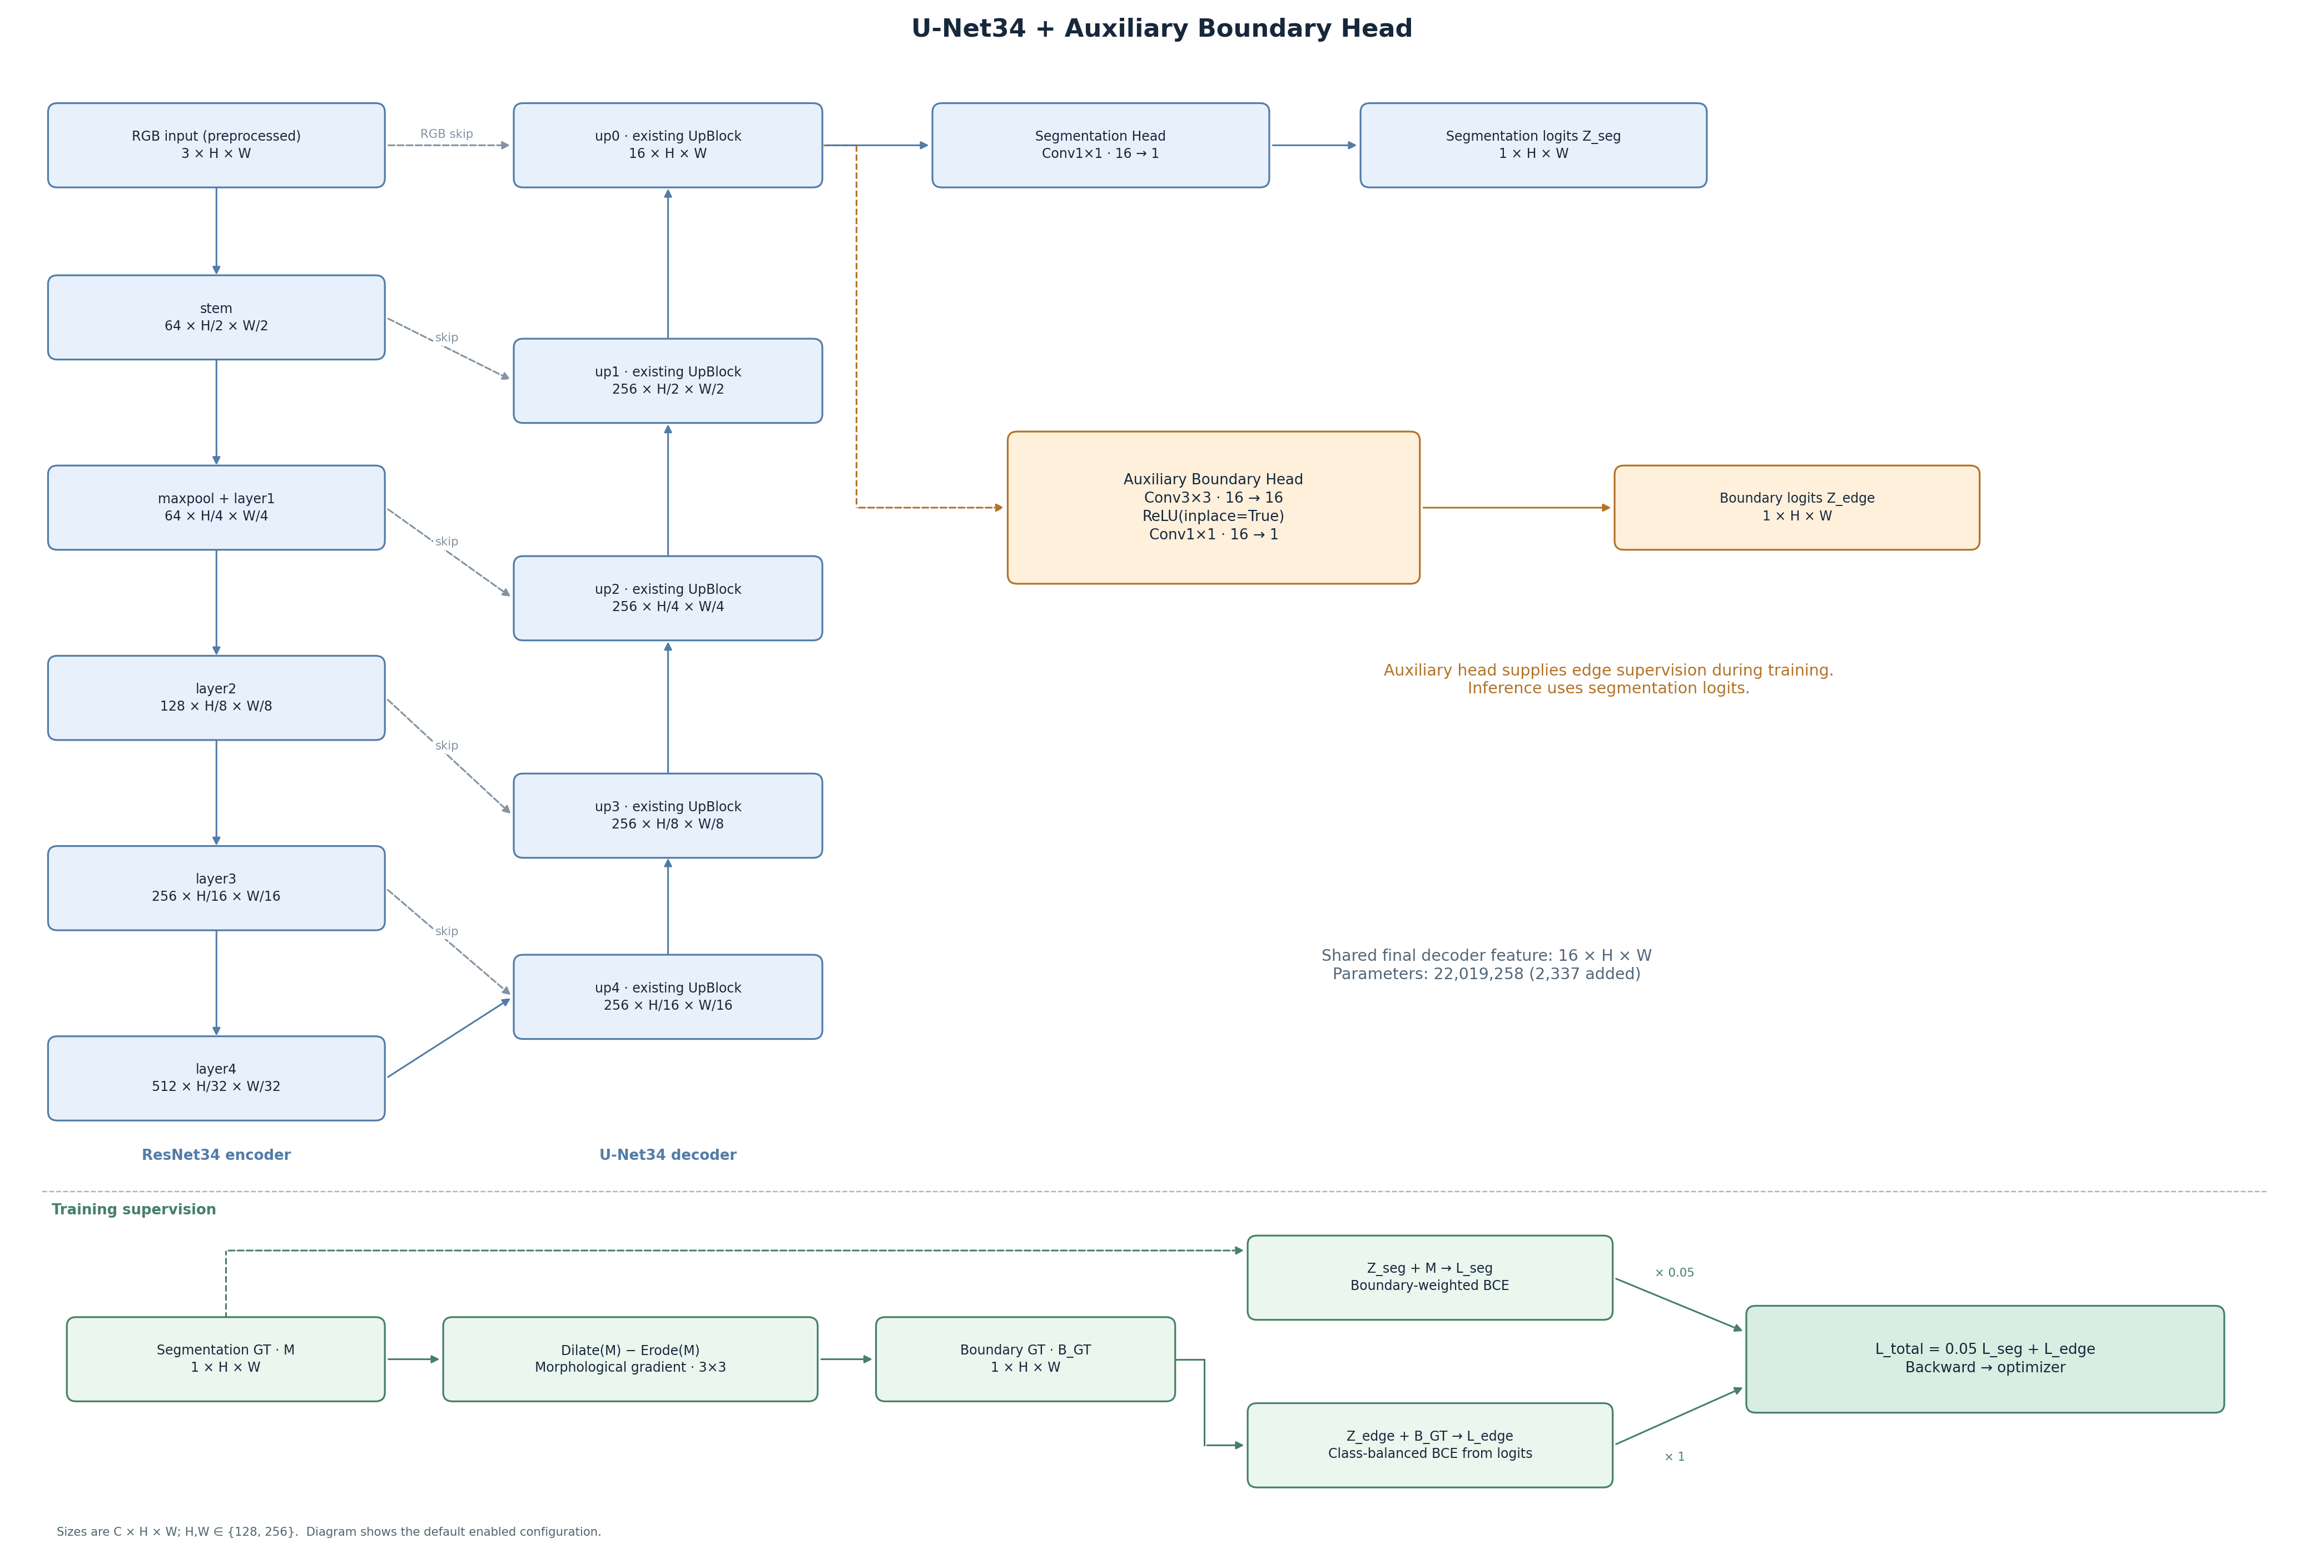

In [ ]:
# Kaggle image đã có PyTorch, torchvision, OpenCV và Albumentations.
# Không pip install giữa session để tránh thay đổi binary/package đang chạy.
print('Using the Kaggle runtime environment.')

In [ ]:
import gc
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

import albumentations as A
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from PIL import Image
from matplotlib.patches import Patch
from torch.utils.data import DataLoader, Dataset, get_worker_info
from torchvision import models
from tqdm.auto import tqdm

try:
    import psutil
except ImportError:
    psutil = None

# -------------------- Cấu hình baseline --------------------
DATASET_HANDLE = 'tinlngnguyn/skin-lesion-segmentation-hus'
DATA_ROOT = Path('/kaggle/input/skin-lesion-segmentation-hus')
SPLIT_DIRECTORIES = {
    'train': ('ISIC2018_Task1-2_Training_Input', 'ISIC2018_Task1_Training_GroundTruth'),
    'validation': ('ISIC2018_Task1-2_Validation_Input', 'ISIC2018_Task1_Validation_GroundTruth'),
}
EXPECTED_COUNTS = {'train': 2594, 'validation': 100}
SEED = 42
N_FOLDS = 3
SIZES = (128, 256)
FROZEN_EPOCHS = 30
UNFROZEN_EPOCHS = 30
PER_GPU_BATCH_BY_SIZE = {128: 16, 256: 8}
NUM_WORKERS = min(2, os.cpu_count() or 1)
PREFETCH_FACTOR = 1
PIN_MEMORY = True
CACHE_RESIZED_IN_RAM = True
DROP_OS_PAGE_CACHE = True
SAVE_LAST_EVERY = 5
LRF_ITERS = 50
LR_MIN, LR_MAX, LRF_BETA = 1e-6, 1.0, 0.9
LR_SELECTION_FACTOR = 0.1
MAX_LR_FROZEN, MAX_LR_UNFROZEN = 3e-3, 1e-3
CUT_FRAC, STLR_RATIO = 0.1, 32.0
WEIGHT_DECAY = 0.0
GRAD_CLIP_NORM = 1.0
PRED_THRESHOLD = 0.5
JACCARD_CUT = 0.65
PRETRAINED = True
USE_CHANNELS_LAST = False
FP32_TRANSPOSED_CONV = True
USE_FUSED_ADAM = False
RESUME = True
FAST_DEV_RUN = False
PROTOCOL_VERSION = 7
COLOR_BALANCE_PERCENT = 1.0
COLOR_BALANCE_SOURCE = 'fredguth/skin-cancer@master/color_balance.py'

# Chỉ cấu hình loss mới; các hyperparameter baseline ở trên giữ nguyên.
USE_BOUNDARY_WEIGHTED_LOSS = True
BOUNDARY_GAMMA = 5.0
BOUNDARY_KERNEL_SIZE = 31

USE_AUX_BOUNDARY_HEAD = True
ALPHA_SEG = 0.05
EDGE_KERNEL_SIZE = 3

if FAST_DEV_RUN:
    SIZES = (128,)
    FROZEN_EPOCHS = UNFROZEN_EPOCHS = 1
    LRF_ITERS = 8

if not hasattr(A, 'D4'):
    raise RuntimeError('Albumentations runtime quá cũ: cần A.D4 và A.Compose(seed=...).')
try:
    A.Compose([], seed=SEED)
except TypeError as error:
    raise RuntimeError('Albumentations runtime không hỗ trợ Compose(seed=...).') from error

OUTPUT_ROOT = Path('/kaggle/working/unet34_boundary_weighted_aux_boundary_head')
AUX_RUN_TAG = (
    f'aux_alpha_{ALPHA_SEG}_kernel_{EDGE_KERNEL_SIZE}'
    if USE_AUX_BOUNDARY_HEAD else 'no_aux_head'
)
LOSS_RUN_TAG = (
    f'boundary_gamma_{BOUNDARY_GAMMA:g}_kernel_{BOUNDARY_KERNEL_SIZE}'
    if USE_BOUNDARY_WEIGHTED_LOSS else 'bce_control'
)
PAPER_LOSS_TAG = f'paper_cbce_alpha{ALPHA_SEG:g}'
RUN_NAME = ('fast_dev_v7_valid_only' if FAST_DEV_RUN
            else 'full_v7_valid_only')
RUN_DIR = OUTPUT_ROOT / PAPER_LOSS_TAG / AUX_RUN_TAG / LOSS_RUN_TAG / RUN_NAME
CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
LOG_DIR = RUN_DIR / 'logs'
for directory in (RUN_DIR, CHECKPOINT_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
    os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed()
cv2.setNumThreads(0)
torch.set_float32_matmul_precision('high')
if not torch.cuda.is_available():
    raise RuntimeError('Hãy bật Accelerator GPU trong Kaggle Settings.')

DEVICE = torch.device('cuda:0')
GPU_COUNT = torch.cuda.device_count()
GPU_NAMES = [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)]
BATCH_SIZE_BY_SIZE = dict(PER_GPU_BATCH_BY_SIZE)  # notebook luôn chỉ dùng cuda:0
USE_AMP = True
print({
    'device': str(DEVICE), 'gpus': GPU_NAMES, 'global_batch': BATCH_SIZE_BY_SIZE,
    'workers': NUM_WORKERS, 'channels_last': USE_CHANNELS_LAST,
    'fp32_upconv': FP32_TRANSPOSED_CONV, 'run_dir': str(RUN_DIR),
})

def memory_status():
    parts = []
    if psutil is not None:
        process = psutil.Process(os.getpid())
        info = process.memory_full_info()
        main_bytes = getattr(info, 'uss', info.rss)
        worker_bytes = 0
        for child in process.children(recursive=True):
            try:
                child_info = child.memory_full_info()
                worker_bytes += getattr(child_info, 'uss', child_info.rss)
            except psutil.Error:
                pass
        parts.extend([f'ram_main={main_bytes / 2**30:.2f}GiB',
                      f'ram_workers={worker_bytes / 2**30:.2f}GiB'])
    allocated = torch.cuda.memory_allocated(0)
    reserved = torch.cuda.memory_reserved(0)
    parts.extend([f'cuda_alloc={allocated / 2**30:.2f}GiB',
                  f'cuda_reserved={reserved / 2**30:.2f}GiB'])
    return ' '.join(parts)

In [ ]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png'}

def find_populated_directory(directory_name, suffixes):
    outer = DATA_ROOT / directory_name
    candidates = [outer / directory_name, outer]
    if DATA_ROOT.is_dir():
        candidates.extend(path for path in DATA_ROOT.rglob(directory_name) if path.is_dir())
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen or not candidate.is_dir():
            continue
        seen.add(candidate)
        if any(path.is_file() and path.suffix.lower() in suffixes
               for path in candidate.iterdir()):
            return candidate
    raise FileNotFoundError(f'Không tìm thấy thư mục dữ liệu {directory_name} dưới {DATA_ROOT}')

def discover_records(split):
    image_name, mask_name = SPLIT_DIRECTORIES[split]
    image_dir = find_populated_directory(image_name, IMAGE_SUFFIXES)
    mask_dir = find_populated_directory(mask_name, {'.png'})
    image_paths = [path for path in image_dir.iterdir()
                   if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES]
    mask_paths = [path for path in mask_dir.iterdir()
                  if path.is_file() and path.suffix.lower() == '.png'
                  and path.stem.endswith('_segmentation')]
    if len({path.stem for path in image_paths}) != len(image_paths):
        raise RuntimeError(f'{split}: trùng image ID')
    image_map = {path.stem: path for path in image_paths}
    mask_map = {path.stem.removesuffix('_segmentation'): path for path in mask_paths}
    if len(mask_map) != len(mask_paths):
        raise RuntimeError(f'{split}: trùng mask ID')
    missing_masks = sorted(set(image_map) - set(mask_map))
    orphan_masks = sorted(set(mask_map) - set(image_map))
    if missing_masks or orphan_masks:
        raise RuntimeError(f'{split}: thiếu mask={missing_masks[:5]}, mask mồ côi={orphan_masks[:5]}')
    records = [
        {'image_id': image_id, 'image_path': image_map[image_id],
         'mask_path': mask_map[image_id]}
        for image_id in sorted(image_map)
    ]
    if len(records) != EXPECTED_COUNTS[split]:
        raise RuntimeError(f'{split}: cần {EXPECTED_COUNTS[split]} cặp, thấy {len(records)}')
    return records, image_dir, mask_dir

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f'Chưa Attach dataset {DATASET_HANDLE}; không thấy {DATA_ROOT}'
    )
train_records_all, train_image_dir, train_mask_dir = discover_records('train')
official_val_records_all, val_image_dir, val_mask_dir = discover_records('validation')

split_ids = {
    'train': {record['image_id'] for record in train_records_all},
    'validation': {record['image_id'] for record in official_val_records_all},
}
assert split_ids['train'].isdisjoint(split_ids['validation'])

def deterministic_subset(records, count, seed):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(records))[:min(count, len(records))]
    return [records[int(index)] for index in indices]

if FAST_DEV_RUN:
    train_records = deterministic_subset(train_records_all, 96, SEED)
    official_val_records = deterministic_subset(official_val_records_all, 24, SEED + 1)
else:
    train_records = train_records_all
    official_val_records = official_val_records_all

generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(train_records), generator=generator).tolist()
fold_sizes = [len(train_records) // N_FOLDS] * N_FOLDS
for index in range(len(train_records) % N_FOLDS):
    fold_sizes[index] += 1
fold_indices, cursor = [], 0
for fold_size in fold_sizes:
    fold_indices.append(permutation[cursor:cursor + fold_size])
    cursor += fold_size
folds, all_indices = [], set(range(len(train_records)))
for holdout_indices in fold_indices:
    holdout_set = set(holdout_indices)
    train_indices = sorted(all_indices - holdout_set)
    train_subset = [train_records[index] for index in train_indices]
    holdout_subset = [train_records[index] for index in holdout_indices]
    assert {r['image_id'] for r in train_subset}.isdisjoint(
        r['image_id'] for r in holdout_subset
    )
    folds.append((train_subset, holdout_subset))

print('pairs:', {'train': len(train_records), 'validation': len(official_val_records)},
      'fold sizes:', fold_sizes)
print('train dirs:', train_image_dir, train_mask_dir, sep='\n  ')
print('validation dirs:', val_image_dir, val_mask_dir, sep='\n  ')

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
RAM_CACHE = {}


def apply_mask(matrix, mask, fill_value):
    masked = np.ma.array(matrix, mask=mask, fill_value=fill_value)
    return masked.filled()


def apply_threshold(matrix, low_value, high_value):
    low_mask = matrix < low_value
    matrix = apply_mask(matrix, low_mask, low_value)

    high_mask = matrix > high_value
    matrix = apply_mask(matrix, high_mask, high_value)

    return matrix


def simplest_cb(img, percent):
    """Thuật toán từ fredguth/skin-cancer/color_balance.py."""
    assert img.shape[2] == 3
    assert percent > 0 and percent < 100

    half_percent = percent / 200.0
    channels = cv2.split(img)

    out_channels = []
    for channel in channels:
        assert len(channel.shape) == 2

        height, width = channel.shape
        vec_size = width * height
        flat = channel.reshape(vec_size)

        assert len(flat.shape) == 1

        flat = np.sort(flat)
        n_cols = flat.shape[0]

        low_val = flat[math.floor(n_cols * half_percent)]
        high_val = flat[math.ceil(n_cols * (1.0 - half_percent))]

        # Bản gốc print low/high ở đây để debug; bỏ print không đổi kết quả.
        thresholded = apply_threshold(channel, low_val, high_val)
        normalized = cv2.normalize(
            thresholded, thresholded.copy(), 0, 255, cv2.NORM_MINMAX
        )
        out_channels.append(normalized)

    return cv2.merge(out_channels)


def load_color_balanced_rgb(path):
    # color_balance.py dùng cv2.imread -> BGR. Giữ đúng thứ tự đó khi balance,
    # rồi mới đổi sang RGB vì encoder pretrained dùng ImageNet RGB.
    image_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise FileNotFoundError(f'OpenCV không đọc được ảnh: {path}')
    if (DROP_OS_PAGE_CACHE and hasattr(os, 'posix_fadvise')
            and hasattr(os, 'POSIX_FADV_DONTNEED')):
        try:
            with open(path, 'rb') as handle:
                os.posix_fadvise(handle.fileno(), 0, 0, os.POSIX_FADV_DONTNEED)
        except OSError:
            pass
    balanced_bgr = simplest_cb(image_bgr, COLOR_BALANCE_PERCENT)
    balanced_rgb = cv2.cvtColor(balanced_bgr, cv2.COLOR_BGR2RGB)
    return balanced_rgb.astype(np.uint8, copy=False)


def load_pil_uint8(path, mode):
    with open(path, 'rb') as handle:
        with Image.open(handle) as source:
            array = np.asarray(source.convert(mode), dtype=np.uint8).copy()
        if (DROP_OS_PAGE_CACHE and hasattr(os, 'posix_fadvise')
                and hasattr(os, 'POSIX_FADV_DONTNEED')):
            try:
                os.posix_fadvise(handle.fileno(), 0, 0, os.POSIX_FADV_DONTNEED)
            except OSError:
                pass
    return array

def build_transform(size, train, seed, preprocessed=False):
    steps = []
    if not preprocessed:
        steps.extend([
            A.Resize(size, size, interpolation=cv2.INTER_LINEAR,
                     mask_interpolation=cv2.INTER_NEAREST),
        ])
    if train:
        steps.extend([
            A.D4(p=1.0),
            A.Affine(rotate=(-44, 44), scale=(1.0, 1.05),
                     interpolation=cv2.INTER_LINEAR,
                     mask_interpolation=cv2.INTER_NEAREST, p=0.75),
            A.RandomBrightnessContrast(brightness_limit=0.2,
                                       contrast_limit=0.2, p=0.75),
        ])
    steps.append(ToTensorV2())
    return A.Compose(steps, seed=int(seed))

class ISICDataset(Dataset):
    def __init__(self, records, size, train, seed=SEED):
        if not records:
            raise ValueError('Dataset rỗng')
        self.records = list(records)
        self.size = int(size)
        self.train = bool(train)
        cache = RAM_CACHE.get(self.size)
        indices = None if cache is None else [cache['id_to_index'].get(r['image_id'])
                                              for r in self.records]
        self.cache = cache if indices is not None and all(i is not None for i in indices) else None
        self.cache_indices = indices if self.cache is not None else None
        self.transform = build_transform(
            self.size, self.train, seed, preprocessed=self.cache is not None
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        if self.cache is not None:
            cache_index = self.cache_indices[index]
            image_np = self.cache['images'][cache_index].copy()
            mask_np = self.cache['masks'][cache_index].copy()
        else:
            image_np = load_color_balanced_rgb(record['image_path'])
            mask_np = load_pil_uint8(record['mask_path'], 'L')
            if image_np.shape[:2] != mask_np.shape:
                raise ValueError(f"Image/mask lệch kích thước: {record['image_id']}")
            mask_np = (mask_np > 127).astype(np.uint8)
        transformed = self.transform(image=image_np, mask=mask_np)
        image, mask = transformed['image'], transformed['mask']
        if mask.ndim == 2:
            mask = mask.unsqueeze(0)
        return image.contiguous(), (mask > 0).float().contiguous()

def seed_worker(worker_id):
    del worker_id
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    worker = get_worker_info()
    if worker is not None and hasattr(worker.dataset.transform, 'set_random_seed'):
        worker.dataset.transform.set_random_seed(worker_seed)

def make_loader(records, size, train, seed, batch_size=None, drop_last=False):
    if batch_size is None:
        batch_size = BATCH_SIZE_BY_SIZE[int(size)]
    kwargs = dict(
        dataset=ISICDataset(records, size, train, seed),
        batch_size=int(batch_size), shuffle=bool(train), drop_last=bool(drop_last),
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=False,
        worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(int(seed)),
    )
    if NUM_WORKERS > 0:
        kwargs['prefetch_factor'] = PREFETCH_FACTOR
    return DataLoader(**kwargs)

def build_ram_caches(records, sizes):
    records = list(records)
    sizes = tuple(dict.fromkeys(int(size) for size in sizes))
    image_ids = [record['image_id'] for record in records]
    if len(image_ids) != len(set(image_ids)):
        raise ValueError('Trùng image_id trong RAM cache')
    caches = {
        size: {
            'images': np.empty((len(records), size, size, 3), dtype=np.uint8),
            'masks': np.empty((len(records), size, size), dtype=np.uint8),
            'id_to_index': {image_id: index for index, image_id in enumerate(image_ids)},
        }
        for size in sizes
    }
    for index, record in enumerate(tqdm(records, desc=f'RAM cache {sizes}px')):
        image_np = load_color_balanced_rgb(record['image_path'])
        mask_np = load_pil_uint8(record['mask_path'], 'L')
        if image_np.shape[:2] != mask_np.shape:
            raise ValueError(f"Image/mask lệch kích thước: {record['image_id']}")
        binary_mask = (mask_np > 127).astype(np.uint8)
        for size in sizes:
            resized = cv2.resize(image_np, (size, size), interpolation=cv2.INTER_LINEAR)
            caches[size]['images'][index] = resized
            caches[size]['masks'][index] = cv2.resize(
                binary_mask, (size, size), interpolation=cv2.INTER_NEAREST
            )
    return caches

if CACHE_RESIZED_IN_RAM:
    RAM_CACHE.update(build_ram_caches(train_records, SIZES))
    cache_gib = sum(v['images'].nbytes + v['masks'].nbytes
                    for v in RAM_CACHE.values()) / 2**30
    print(f'Train-only color-balanced + resized uint8 cache: {cache_gib:.2f} GiB | {memory_status()}')

clean_dataset = ISICDataset(train_records[:3], SIZES[0], train=False)
for index in range(len(clean_dataset)):
    x1, y1 = clean_dataset[index]
    x2, y2 = clean_dataset[index]
    assert torch.equal(x1, x2) and torch.equal(y1, y2)
    assert x1.dtype == torch.uint8 and y1.dtype == torch.float32
    assert set(torch.unique(y1).tolist()).issubset({0.0, 1.0})
    assert 0.0 < float(y1.mean()) < 1.0
del clean_dataset, x1, x2, y1, y2
print('Dataset, mask and clean-transform checks: OK')

In [ ]:
class UpBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels // 2, 2, stride=2)
        self.skip_projection = nn.Conv2d(skip_channels, out_channels // 2, 1)
        self.bn = nn.BatchNorm2d(out_channels)

    def forward(self, x, skip):
        source_dtype = x.dtype
        if FP32_TRANSPOSED_CONV and x.is_cuda:
            with torch.autocast(device_type='cuda', enabled=False):
                x = self.up(x.float())
            x = x.to(dtype=source_dtype)
        else:
            x = self.up(x)
        skip = self.skip_projection(skip)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode='nearest')
        return self.bn(F.relu(torch.cat([x, skip], dim=1)))

class UNet34(nn.Module):
    def __init__(self, pretrained=True, *, use_aux_boundary_head=None):
        super().__init__()
        weights = models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None
        try:
            backbone = models.resnet34(weights=weights)
        except Exception as error:
            raise RuntimeError(
                'Không tải được ResNet34 ImageNet weights; hãy bật Internet trong Kaggle.'
            ) from error
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)
        self.pool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4
        self.up4 = UpBlock(512, 256, 256)
        self.up3 = UpBlock(256, 128, 256)
        self.up2 = UpBlock(256, 64, 256)
        self.up1 = UpBlock(256, 64, 256)
        self.up0 = UpBlock(256, 3, 16)
        self.head = nn.Conv2d(16, 1, 1)
        if use_aux_boundary_head is None:
            use_aux_boundary_head = USE_AUX_BOUNDARY_HEAD
        if use_aux_boundary_head:
            # up0 feeds the segmentation head at full resolution (16 channels).
            # Preserve the RNG sequence of the segmentation-only run.
            with torch.random.fork_rng(devices=[]):
                self.boundary_head = nn.Sequential(
                    nn.Conv2d(self.head.in_channels, 16, kernel_size=3, padding=1),
                    nn.ReLU(inplace=True),
                    nn.Conv2d(16, 1, kernel_size=1),
                )

    @property
    def first_layer_group(self):
        return (self.stem, self.layer1, self.layer2)

    def forward(self, x, *, return_boundary=False):
        s0 = self.stem(x)
        s1 = self.layer1(self.pool(s0))
        s2 = self.layer2(s1)
        s3 = self.layer3(s2)
        bottleneck = self.layer4(s3)
        decoded = self.up4(bottleneck, s3)
        decoded = self.up3(decoded, s2)
        decoded = self.up2(decoded, s1)
        decoded = self.up1(decoded, s0)
        decoded = self.up0(decoded, x)
        segmentation_logits = self.head(decoded)
        if return_boundary:
            if not hasattr(self, 'boundary_head'):
                raise RuntimeError('Auxiliary Boundary Head đang tắt')
            return segmentation_logits, self.boundary_head(decoded)
        return segmentation_logits

def unwrap_model(model):
    return model

def to_runtime(model):
    model = model.to(DEVICE)
    if USE_CHANNELS_LAST:
        model = model.to(memory_format=torch.channels_last)
    return model  # intentionally use only cuda:0

def freeze_first_layer_group(model):
    base = unwrap_model(model)
    for parameter in base.parameters():
        parameter.requires_grad = True
    for module in base.first_layer_group:
        for child in module.modules():
            for parameter in child.parameters(recurse=False):
                parameter.requires_grad = isinstance(child, nn.BatchNorm2d)

def unfreeze_with_frozen_bn(model):
    for parameter in model.parameters():
        parameter.requires_grad = True
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            for parameter in module.parameters():
                parameter.requires_grad = False

def set_train_mode(model, freeze_bn):
    model.train()
    if freeze_bn:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

def cpu_state_dict(model):
    return {key: value.detach().cpu().clone()
            for key, value in unwrap_model(model).state_dict().items()}

@torch.no_grad()
def refresh_cpu_state_dict(model, destination):
    source = unwrap_model(model).state_dict()
    if tuple(source) != tuple(destination):
        raise RuntimeError('state_dict keys changed during training')
    for key, value in source.items():
        destination[key].copy_(value.detach(), non_blocking=False)

def load_model_state(model, state):
    while state and all(key.startswith('module.') for key in state):
        state = {key.removeprefix('module.'): value for key, value in state.items()}
    unwrap_model(model).load_state_dict(state)

shape_model = UNet34(pretrained=False).eval()
with torch.inference_mode():
    shape_output = shape_model(torch.randn(2, 3, 128, 128))
assert shape_output.shape == (2, 1, 128, 128)
assert not any(key.startswith('first_layer_group.') for key in shape_model.state_dict())
print(f'Parameters: {sum(p.numel() for p in shape_model.parameters()) / 1e6:.3f}M')
del shape_model, shape_output

## Boundary-weighted BCE: công thức và đối chiếu nguồn

Với logits $Z$ và mask ground truth $M\in\{0,1\}^{N\times1\times H\times W}$ ở **cùng độ phân giải**, đặt

$$A=\left|\operatorname{AvgPool}_{31,\,1,\,15}(M)-M\right|,\qquad W=1+\gamma A,$$

$$L_{\mathrm{BW\text{-}BCE}}=\frac{1}{NC}\sum_{n,c}
\frac{\sum_{h,w}W_{nchw}\,\operatorname{BCEWithLogits}(Z_{nchw},M_{nchw})}
{\max(\sum_{h,w}W_{nchw},10^{-8})},\qquad C=1.$$

`BOUNDARY_GAMMA=5.0`, `BOUNDARY_KERNEL_SIZE=31`, stride 1, padding 15.
Đây là **thay thế BCE bằng BCE có trọng số pixel**, không cộng thêm một loss thứ hai.
Không sigmoid trước BCEWithLogits; sigmoid trong metrics/inference của baseline giữ nguyên.
Chuẩn hóa theo tổng $W$ riêng từng mẫu/kênh rồi mới lấy trung bình, không chia cho số pixel hoặc tổng $W$ của cả batch.

| Nguồn đã đối chiếu | Boundary weight, chuẩn hóa và hệ số | Áp dụng trong notebook |
|---|---|---|
| [F³Net, AAAI 2020 — paper](https://arxiv.org/abs/1911.11445), [repo](https://github.com/weijun-arc/F3Net), [src/train.py](https://github.com/weijun-arc/F3Net/blob/master/src/train.py) | Paper Eq. (4) dùng sai khác mask với trung bình lân cận; Table 3 so sánh $\gamma=3,4,5,6$ và chọn 5 trên dữ liệu saliency. Code dùng $1+5A$, AvgPool 31/1/15, chia weighted BCE cho tổng trọng số; full PPA còn có weighted IoU. | Chỉ lấy weighted BCE. Lưu ý Eq. (3) bản arXiv in mẫu số $\sum\gamma A$, khác code $\sum(1+\gamma A)$; notebook theo **code tham khảo và công thức yêu cầu**, bảo đảm $\gamma=0$ trở về BCE. |
| [CaraNet — Train.py, structure_loss](https://github.com/AngeLouCN/CaraNet/blob/main/Train.py) | Dùng cùng $1+5|\operatorname{AvgPool}_{31,1,15}(M)-M|$, tổng $W\cdot\mathrm{BCE}$ chia tổng $W$ theo H/W, rồi mean; full structure loss cộng weighted IoU với hệ số 1. Code cũ ghi `reduce='none'`. | Giữ kernel 31 và ý nghĩa chuẩn hóa; dùng API đúng `reduction='none'` để thực sự nhận BCE từng pixel. Không chép weighted IoU hoặc multi-output supervision. |
| [SL-HarDNet — skin lesion segmentation](https://pmc.ncbi.nlm.nih.gov/articles/PMC9849244/) | Mục 3.6, Eq. (19)–(22): kết hợp weighted IoU và weighted BCE, cộng loss cho hai output với hệ số ngầm định 1. Phần này không nêu tường minh công thức weight map, kernel, gamma hoặc mẫu số chuẩn hóa. | Là đối chiếu ứng dụng trên tổn thương da; không gán kernel 31/gamma 5 cho bài này khi bài không chỉ rõ. Không lấy cấu trúc hai output hay full combination loss. |
| [Boundary Guidance Network — Scientific Reports 2024](https://www.nature.com/articles/s41598-024-67554-0), [bản toàn văn PMC](https://pmc.ncbi.nlm.nih.gov/articles/PMC11284230/) | Eq. (7) chia weighted BCE cho $N$ pixel. $w_i\in[1,5]$ theo khoảng cách Chebyshev: biên có trọng số 5, khoảng suy giảm 3 pixel, hệ số suy giảm 1, vùng chồng lấy max. Eq. (10) kết hợp BCE/mIoU/Dice với $(\alpha,\beta,\gamma)=(1,1,2)$. | Đây là cách dựng trọng số và chuẩn hóa **khác** AvgPool. $\gamma=2$ của bài là hệ số phối hợp loss, không phải `BOUNDARY_GAMMA`. Không đưa boundary head, mIoU hoặc Dice vào thí nghiệm này. |

**Ý nghĩa trọng số.** $A\in[0,1]$, nên $W\in[1,6]$ khi gamma=5; gamma=5 không có nghĩa mọi pixel biên có trọng số đúng bằng 5. Vùng đồng nhất xa biên có $W=1$; vùng chuyển tiếp, cấu trúc mảnh, lỗ và tổn thương nhỏ có thể được tăng trọng số. Giữ mặc định PyTorch `count_include_pad=True`: zero padding cũng có thể làm tăng trọng số foreground chạm mép ảnh. Không dùng distance transform hoặc signed distance map; phương pháp này khác [distance-based Boundary Loss của Kervadec và cộng sự](https://proceedings.mlr.press/v102/kervadec19a.html).

**Kernel cố định.** 31 pixel tương ứng khoảng **24,2%** chiều ảnh 128px và **12,1%** chiều ảnh 256px. Phạm vi tương đối khác nhau giữa hai training stages; không tự scale kernel nếu chưa có thí nghiệm riêng. Giá trị gamma=5 là lựa chọn tham khảo từ F³Net, chưa phải kết luận tối ưu cho ISIC.

**Ablation.** Đặt `USE_BOUNDARY_WEIGHTED_LOSS=False` rồi Restart & Run All để dùng đúng `nn.BCEWithLogitsLoss()` ban đầu; `True` dùng BW-BCE cho nhánh segmentation. Cả hai nhánh lưu trong thư mục riêng với baseline gốc và riêng với nhau. LR Finder, quy tắc chọn LR, optimizer, STLR, các stages, Best Dice checkpoint, ensemble và metrics giữ nguyên. Vì LR Finder vẫn dùng training loss hiện tại như baseline, giá trị LR mà nó chọn có thể khác giữa hai nhánh; thuật toán và giới hạn LR không đổi. Các cell bổ sung không thay đổi RNG của training.

In [ ]:
@torch.no_grad()
def boundary_weight_map(mask, gamma=5.0, kernel_size=31):
    """Ground-truth-only local contrast weights; never edit or resize mask."""
    if mask.ndim != 4:
        raise ValueError('mask cần có dạng N,C,H,W')
    if not math.isfinite(float(gamma)) or gamma < 0:
        raise ValueError('gamma phải hữu hạn và >= 0')
    if not isinstance(kernel_size, int) or kernel_size <= 0 or kernel_size % 2 != 1:
        raise ValueError('kernel_size phải là số nguyên dương lẻ')
    # FP32 reductions remain stable inside the existing FP16 AMP training context.
    # detach()/float() do not modify the ground-truth tensor in place.
    with torch.autocast(device_type=mask.device.type, enabled=False):
        target = mask.detach().float()
        return 1 + gamma * torch.abs(
            F.avg_pool2d(
                target, kernel_size=kernel_size, stride=1,
                padding=kernel_size // 2, count_include_pad=True,
            ) - target
        )


class BoundaryWeightedBCEWithLogitsLoss(nn.Module):
    """Only weighted BCE; no sigmoid, IoU, Dice, distance map or extra outputs."""
    def __init__(self, gamma=5.0, kernel_size=31):
        super().__init__()
        if not math.isfinite(float(gamma)) or gamma < 0:
            raise ValueError('gamma phải hữu hạn và >= 0')
        if not isinstance(kernel_size, int) or kernel_size <= 0 or kernel_size % 2 != 1:
            raise ValueError('kernel_size phải là số nguyên dương lẻ')
        self.gamma = float(gamma)
        self.kernel_size = kernel_size

    def forward(self, logits, mask):
        if logits.ndim != 4 or logits.shape != mask.shape:
            raise ValueError('logits và mask phải cùng shape N,C,H,W; không tự resize GT')
        if logits.device != mask.device:
            raise ValueError('logits và mask phải trên cùng device')
        with torch.autocast(device_type=logits.device.type, enabled=False):
            target = mask.detach().float()
            weight = boundary_weight_map(target, self.gamma, self.kernel_size)
            bce = F.binary_cross_entropy_with_logits(
                logits.float(), target, reduction='none'
            )
            weighted_bce = (
                (weight * bce).sum(dim=(2, 3))
                / weight.sum(dim=(2, 3)).clamp_min(1e-8)
            ).mean()
        return weighted_bce

In [ ]:
criterion = (
    BoundaryWeightedBCEWithLogitsLoss(
        gamma=BOUNDARY_GAMMA, kernel_size=BOUNDARY_KERNEL_SIZE
    )
    if USE_BOUNDARY_WEIGHTED_LOSS else nn.BCEWithLogitsLoss()
)
INPUT_DTYPE = torch.float16 if USE_AMP else torch.float32
GPU_MEAN = torch.tensor(IMAGENET_MEAN, device=DEVICE, dtype=INPUT_DTYPE).view(1, 3, 1, 1)
GPU_STD = torch.tensor(IMAGENET_STD, device=DEVICE, dtype=INPUT_DTYPE).view(1, 3, 1, 1)

def prepare_inputs(inputs):
    inputs = inputs.to(DEVICE, non_blocking=True).to(dtype=INPUT_DTYPE)
    inputs.div_(255.0).sub_(GPU_MEAN).div_(GPU_STD)
    if USE_CHANNELS_LAST:
        return inputs.contiguous(memory_format=torch.channels_last)
    return inputs.contiguous()

def per_image_dice(probability, target, threshold=PRED_THRESHOLD):
    prediction = (probability > threshold).float()
    dims = (1, 2, 3)
    intersection = (prediction * target).sum(dims)
    denominator = prediction.sum(dims) + target.sum(dims)
    return torch.where(denominator > 0, 2 * intersection / denominator.clamp(min=1),
                       torch.ones_like(denominator))

@torch.inference_mode()
def evaluate_holdout_metrics(model, loader):
    model.eval()
    metric_sums = torch.zeros(2, device=DEVICE, dtype=torch.float32)
    sample_count = 0
    for inputs, targets in loader:
        inputs = prepare_inputs(inputs)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            probability = torch.sigmoid(model(inputs).float())
        if not bool(torch.isfinite(probability).all()):
            raise FloatingPointError('Model sinh xác suất NaN/Inf')
        prediction = (probability > PRED_THRESHOLD).float()
        dims = (1, 2, 3)
        intersection = (prediction * targets).sum(dims)
        prediction_sum = prediction.sum(dims)
        target_sum = targets.sum(dims)
        denominator = prediction_sum + target_sum
        dice = torch.where(
            denominator > 0,
            2 * intersection / denominator.clamp(min=1),
            torch.ones_like(denominator),
        )
        union = prediction_sum + target_sum - intersection
        jaccard = torch.where(
            union > 0, intersection / union.clamp(min=1), torch.ones_like(union)
        )
        metric_sums[0] += dice.sum()
        metric_sums[1] += (jaccard * (jaccard >= JACCARD_CUT)).sum()
        sample_count += targets.shape[0]
    if sample_count == 0:
        raise RuntimeError('Holdout loader rỗng')
    dice, threshold_jaccard = (metric_sums / sample_count).cpu().tolist()
    return {
        'dice': float(dice),
        'threshold_jaccard': float(threshold_jaccard),
    }

def evaluate_dice(model, loader):
    return evaluate_holdout_metrics(model, loader)['dice']

def per_image_scores(probability, target, threshold=PRED_THRESHOLD):
    prediction = (probability > threshold).float()
    dims = (1, 2, 3)
    intersection = (prediction * target).sum(dims)
    prediction_sum = prediction.sum(dims)
    target_sum = target.sum(dims)
    union = prediction_sum + target_sum - intersection
    jaccard = torch.where(union > 0, intersection / union.clamp(min=1),
                           torch.ones_like(union))
    dice = torch.where(prediction_sum + target_sum > 0,
                       2 * intersection / (prediction_sum + target_sum).clamp(min=1),
                       torch.ones_like(union))
    sensitivity = torch.where(target_sum > 0,
                              intersection / target_sum.clamp(min=1),
                              torch.ones_like(target_sum))
    return jaccard, dice, sensitivity

# -------------------- T4 GPU evaluation backend --------------------
# Inference, Dice/IoU/Sensitivity and HD95 stay on CUDA.
# HD95 uses surface-to-surface Euclidean distance on GPU. The source/target
# boundary points are chunked so torch.cdist does not create a huge matrix.
EVAL_BATCH_SIZE = 16
HD95_SOURCE_CHUNK = 1024
HD95_TARGET_CHUNK = 4096

HD95_CROSS_KERNEL = torch.tensor(
    [[0.0, 1.0, 0.0],
     [1.0, 1.0, 1.0],
     [0.0, 1.0, 0.0]],
    device=DEVICE, dtype=torch.float32,
).view(1, 1, 3, 3)


def mask_surface_batch_gpu(masks):
    """Equivalent to scipy.ndimage.binary_erosion(mask) XOR mask for 2-D masks."""
    masks = masks.bool()
    neighborhood_count = F.conv2d(
        masks[:, None].float(), HD95_CROSS_KERNEL, padding=1
    )[:, 0]
    eroded = masks & (neighborhood_count == 5.0)
    return masks & ~eroded


def min_surface_distance_gpu(source_coords, target_coords):
    """Nearest Euclidean distance for every source point, memory-bounded on CUDA."""
    source_coords = source_coords.to(dtype=torch.float32)
    target_coords = target_coords.to(dtype=torch.float32)
    outputs = []
    for source_chunk in source_coords.split(HD95_SOURCE_CHUNK):
        chunk_min = torch.full(
            (source_chunk.shape[0],), float('inf'),
            device=source_chunk.device, dtype=torch.float32,
        )
        for target_chunk in target_coords.split(HD95_TARGET_CHUNK):
            distances = torch.cdist(source_chunk, target_chunk, p=2)
            chunk_min = torch.minimum(chunk_min, distances.amin(dim=1))
        outputs.append(chunk_min)
    return torch.cat(outputs, dim=0)


def hd95_batch_sum_gpu(prediction_masks, target_masks,
                       target_surfaces=None, target_nonempty=None):
    """
    Sum HD95 over a batch on GPU.
    Definition matches the old CPU implementation:
    95th percentile of bidirectional surface-to-surface distances.
    """
    prediction_masks = prediction_masks.bool()
    target_masks = target_masks.bool()

    if target_surfaces is None:
        target_surfaces = mask_surface_batch_gpu(target_masks)
    prediction_surfaces = mask_surface_batch_gpu(prediction_masks)

    prediction_nonempty = prediction_masks.flatten(1).any(dim=1).cpu().tolist()
    if target_nonempty is None:
        target_nonempty = target_masks.flatten(1).any(dim=1).cpu().tolist()

    height, width = target_masks.shape[-2:]
    empty_penalty = float(math.hypot(height, width))
    total = torch.zeros((), device=DEVICE, dtype=torch.float32)

    for batch_index, (pred_has_pixels, target_has_pixels) in enumerate(
        zip(prediction_nonempty, target_nonempty)
    ):
        if not pred_has_pixels and not target_has_pixels:
            continue
        if not pred_has_pixels or not target_has_pixels:
            total += empty_penalty
            continue

        prediction_coords = prediction_surfaces[batch_index].nonzero(as_tuple=False)
        target_coords = target_surfaces[batch_index].nonzero(as_tuple=False)

        pred_to_target = min_surface_distance_gpu(prediction_coords, target_coords)
        target_to_pred = min_surface_distance_gpu(target_coords, prediction_coords)
        distances = torch.cat((pred_to_target, target_to_pred), dim=0)
        total += torch.quantile(distances, 0.95)

    return total


@torch.inference_mode()
def model_probability_gpu(model, inputs):
    model.eval()
    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
        return torch.sigmoid(model(inputs).float())


def accumulate_variant_gpu(metric_sum, probability, targets_device,
                           target_masks, target_surfaces, target_nonempty,
                           include_hd95):
    jaccard, dice, sensitivity = per_image_scores(probability, targets_device)
    metric_sum[0] += jaccard.sum()
    metric_sum[1] += (jaccard * (jaccard >= JACCARD_CUT)).sum()
    metric_sum[2] += dice.sum()
    metric_sum[3] += sensitivity.sum()

    if include_hd95:
        prediction_masks = probability[:, 0] > PRED_THRESHOLD
        metric_sum[4] += hd95_batch_sum_gpu(
            prediction_masks,
            target_masks,
            target_surfaces=target_surfaces,
            target_nonempty=target_nonempty,
        )
    return jaccard, dice, sensitivity


@torch.inference_mode()
def evaluate_variants_gpu(models_list, loader, individual_indices=(),
                          include_ensemble=True, include_hd95=True,
                          sample_ids=None):
    """
    Evaluate requested single models + equal-weight ensemble in ONE loader pass.
    Each model is forwarded only once per batch; probabilities are reused.
    """
    if not models_list:
        raise ValueError('models_list rỗng')
    if sample_ids is not None and not include_ensemble:
        raise ValueError('sample_ids yêu cầu include_ensemble=True')
    sample_ids = None if sample_ids is None else list(sample_ids)

    individual_indices = tuple(dict.fromkeys(int(i) for i in individual_indices))
    if any(i < 0 or i >= len(models_list) for i in individual_indices):
        raise IndexError('individual_indices ngoài phạm vi models_list')

    variant_keys = [f'model_{i}' for i in individual_indices]
    if include_ensemble:
        variant_keys.append('ensemble')

    metric_sums = {
        key: torch.zeros(5, device=DEVICE, dtype=torch.float32)
        for key in variant_keys
    }
    sample_count = 0
    per_image_rows = []
    detail_cursor = 0

    for inputs, targets in loader:
        inputs = prepare_inputs(inputs)
        targets_device = targets.to(DEVICE, non_blocking=True)
        target_masks = targets_device[:, 0] > 0.5

        target_surfaces = None
        target_nonempty = None
        if include_hd95:
            target_surfaces = mask_surface_batch_gpu(target_masks)
            target_nonempty = target_masks.flatten(1).any(dim=1).cpu().tolist()

        probabilities = []
        finite_flags = []
        for model in models_list:
            probability = model_probability_gpu(model, inputs)
            probabilities.append(probability)
            finite_flags.append(torch.isfinite(probability).all())

        if not bool(torch.stack(finite_flags).all()):
            raise FloatingPointError('Model sinh xác suất NaN/Inf khi evaluation')

        for model_index in individual_indices:
            accumulate_variant_gpu(
                metric_sums[f'model_{model_index}'],
                probabilities[model_index],
                targets_device,
                target_masks,
                target_surfaces,
                target_nonempty,
                include_hd95,
            )

        if include_ensemble:
            ensemble_probability = torch.zeros_like(probabilities[0])
            for probability in probabilities:
                ensemble_probability.add_(probability)
            ensemble_probability.div_(len(probabilities))
            jaccard, dice, sensitivity = accumulate_variant_gpu(
                metric_sums['ensemble'],
                ensemble_probability,
                targets_device,
                target_masks,
                target_surfaces,
                target_nonempty,
                include_hd95,
            )
            if sample_ids is not None:
                batch_count = targets_device.shape[0]
                batch_ids = sample_ids[detail_cursor:detail_cursor + batch_count]
                if len(batch_ids) != batch_count:
                    raise RuntimeError('Số sample_id ngắn hơn validation loader')
                predicted_pixels = (
                    ensemble_probability > PRED_THRESHOLD
                ).flatten(1).sum(dim=1)
                target_pixels = target_masks.flatten(1).sum(dim=1)
                values = torch.stack((
                    jaccard, dice, sensitivity,
                    predicted_pixels.float(), target_pixels.float(),
                ), dim=1).detach().cpu().tolist()
                for image_id, row_values in zip(batch_ids, values):
                    image_jaccard, image_dice, image_sensitivity, pred_px, target_px = row_values
                    per_image_rows.append({
                        'image_id': image_id,
                        'jaccard': float(image_jaccard),
                        'threshold_jaccard': float(
                            image_jaccard if image_jaccard >= JACCARD_CUT else 0.0
                        ),
                        'dice': float(image_dice),
                        'sensitivity': float(image_sensitivity),
                        'predicted_pixels': int(pred_px),
                        'target_pixels': int(target_px),
                    })
                detail_cursor += batch_count

        sample_count += targets_device.shape[0]

    if sample_count == 0:
        raise RuntimeError('Evaluation loader rỗng')
    if sample_ids is not None and detail_cursor != len(sample_ids):
        raise RuntimeError(
            f'Validation loader trả {detail_cursor} mẫu nhưng có {len(sample_ids)} ID'
        )

    # Only one GPU -> CPU synchronization per final result vector.
    results = {}
    names = ('jaccard', 'threshold_jaccard', 'dice', 'sensitivity', 'hd95')
    for key, metric_sum in metric_sums.items():
        values = (metric_sum / sample_count).detach().cpu().tolist()
        result = {
            'jaccard': float(values[0]),
            'threshold_jaccard': float(values[1]),
            'dice': float(values[2]),
            'sensitivity': float(values[3]),
        }
        if include_hd95:
            result['hd95'] = float(values[4])
        results[key] = result
    if sample_ids is not None:
        return results, per_image_rows
    return results


metric_target = torch.zeros(2, 1, 8, 8, device=DEVICE)
metric_target[0, :, :4] = 1
metric_target[1, :, :, :4] = 1
metric_probability = metric_target.clone()
metric_probability[1] = 0
metric_probability[1, :, :, :2] = 1
assert torch.allclose(per_image_dice(metric_probability, metric_target),
                      torch.tensor([1.0, 2 / 3], device=DEVICE), atol=1e-6)
del metric_target, metric_probability
print('Dice metric check: OK')

## Kiểm tra loss và tính bất biến của mô hình

Cell sau kiểm tra cả 128px và 256px: gamma=0 bằng BCE về giá trị/gradient, công thức gradient có trọng số, mask rỗng/đầy/tổn thương nhỏ, NaN/Inf, logits cực trị, AMP trên CUDA, mask/logits không bị sửa, lỗi khi lệch độ phân giải, shape output và **22.016.921 tham số** như class U-Net34 nguồn. Model kiểm tra độc lập, không tải pretrained weights; trạng thái RNG CPU/CUDA được bảo toàn bằng `torch.random.fork_rng`. Cell preflight gốc tiếp tục kiểm tra một bước training thật với batch size baseline ở từng stage. Báo cáo được lưu tại `RUN_DIR / 'boundary_loss_checks.json'`.

In [ ]:
def run_boundary_loss_checks():
    report = {'baseline_parameter_count': 22016921, 'sizes': [], 'passed': False}
    cuda_devices = list(range(torch.cuda.device_count())) if DEVICE.type == 'cuda' else []
    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(SEED + 2020)
        baseline_bce = nn.BCEWithLogitsLoss()
        gamma_zero = BoundaryWeightedBCEWithLogitsLoss(gamma=0.0, kernel_size=31)
        weighted = BoundaryWeightedBCEWithLogitsLoss(gamma=BOUNDARY_GAMMA,
                                                    kernel_size=BOUNDARY_KERNEL_SIZE)
        assert len(list(weighted.parameters())) == 0
        assert len(weighted.state_dict()) == 0
        if USE_BOUNDARY_WEIGHTED_LOSS:
            assert isinstance(criterion, BoundaryWeightedBCEWithLogitsLoss)
        else:
            assert type(criterion) is nn.BCEWithLogitsLoss
            assert criterion.reduction == 'mean'

        probe = UNet34(pretrained=False, use_aux_boundary_head=False).to(DEVICE).eval()
        parameter_count = sum(p.numel() for p in probe.parameters())
        assert parameter_count == report['baseline_parameter_count']
        assert probe.head.out_channels == 1

        for size in sorted(set((128, 256, *SIZES))):
            mask = torch.zeros(4, 1, size, size, device=DEVICE)
            mask[1] = 1.0                         # full foreground + padding behavior
            mask[2, :, size // 4:3 * size // 4, size // 4:3 * size // 4] = 1.0
            mask[3, :, size // 2:size // 2 + 2, size // 2:size // 2 + 2] = 1.0
            original_mask = mask.clone()
            logits = torch.randn_like(mask).requires_grad_()
            original_logits = logits.detach().clone()
            weights = boundary_weight_map(mask, BOUNDARY_GAMMA, BOUNDARY_KERNEL_SIZE)
            assert weights.shape == mask.shape and not weights.requires_grad
            assert bool(torch.isfinite(weights).all())
            assert float(weights.min()) >= 1.0
            assert float(weights.max()) <= 1.0 + BOUNDARY_GAMMA + 1e-6
            assert torch.equal(boundary_weight_map(mask, 0.0, 31), torch.ones_like(mask))

            reference = baseline_bce(logits, mask)
            zero_loss = gamma_zero(logits, mask)
            torch.testing.assert_close(zero_loss, reference, rtol=1e-6, atol=1e-7)
            reference_grad = torch.autograd.grad(reference, logits)[0]
            zero_grad = torch.autograd.grad(zero_loss, logits)[0]
            torch.testing.assert_close(zero_grad, reference_grad, rtol=1e-6, atol=1e-8)

            loss = weighted(logits, mask)
            assert loss.ndim == 0 and bool(torch.isfinite(loss))
            loss.backward()
            assert logits.grad is not None and bool(torch.isfinite(logits.grad).all())
            assert float(logits.grad.abs().sum()) > 0.0
            # Independent analytic derivative checks spatial normalization and no extra sigmoid.
            expected_grad = (weights * (logits.detach().sigmoid() - mask)
                             / weights.sum((2, 3), keepdim=True)
                             / (mask.shape[0] * mask.shape[1]))
            torch.testing.assert_close(logits.grad, expected_grad, rtol=2e-5, atol=1e-8)
            # Each sample is normalized separately, including masks of different areas.
            sample_average = torch.stack([
                weighted(logits.detach()[i:i + 1], mask[i:i + 1])
                for i in range(mask.shape[0])
            ]).mean()
            torch.testing.assert_close(loss.detach(), sample_average)
            torch.testing.assert_close(criterion(logits.detach(), mask),
                                       loss.detach() if USE_BOUNDARY_WEIGHTED_LOSS
                                       else reference.detach())

            extreme_logits = torch.full_like(mask, 100.0)
            extreme_logits[::2] = -100.0
            extreme_logits.requires_grad_()
            extreme_loss = weighted(extreme_logits, mask)
            extreme_loss.backward()
            assert bool(torch.isfinite(extreme_loss))
            assert bool(torch.isfinite(extreme_logits.grad).all())

            amp_checked = False
            if DEVICE.type == 'cuda':
                amp_logits = logits.detach().half().requires_grad_()
                with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                    amp_loss = weighted(amp_logits, mask)
                fp32_loss = weighted(amp_logits.detach().float(), mask)
                torch.testing.assert_close(amp_loss, fp32_loss, rtol=1e-6, atol=1e-7)
                amp_loss.backward()
                assert amp_loss.dtype == torch.float32
                assert bool(torch.isfinite(amp_logits.grad).all())
                amp_checked = True

            assert torch.equal(mask, original_mask)
            assert torch.equal(logits.detach(), original_logits)
            assert mask.grad is None
            try:
                weighted(logits.detach(), mask[..., :-1, :])
            except ValueError:
                pass
            else:
                raise AssertionError('Không được âm thầm resize hoặc broadcast mask')

            with torch.inference_mode():
                output = probe(torch.zeros(1, 3, size, size, device=DEVICE))
            assert output.shape == (1, 1, size, size)
            assert sum(p.numel() for p in probe.parameters()) == parameter_count
            report['sizes'].append({
                'size': size, 'gamma0_bce_abs_error': float((zero_loss - reference).detach().abs()),
                'weight_min': float(weights.min()), 'weight_max': float(weights.max()),
                'weight_mean': float(weights.mean()), 'finite_gradient': True,
                'mask_unchanged': True, 'logits_unchanged': True,
                'output_shape': list(output.shape), 'amp_cuda_checked': amp_checked,
            })
            del mask, original_mask, logits, original_logits, weights, output
        del probe
    report['parameter_count'] = parameter_count
    report['device'] = str(DEVICE)
    report['passed'] = True
    (RUN_DIR / 'boundary_loss_checks.json').write_text(
        json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8'
    )
    print(json.dumps(report, indent=2, ensure_ascii=False))
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return report


boundary_loss_check_report = run_boundary_loss_checks()

## Trực quan hóa weight map trên ảnh train

Chọn xác định hai tổn thương nhỏ nhất, hai tổn thương lớn theo tỷ lệ foreground (ưu tiên 40–85% để còn thấy biên trong ảnh; nếu thiếu thì lấy theo diện tích giảm dần) và hai biên không đều nhất trong các mask train còn lại (điểm $P^2/(4\pi A)$, $P$ là tổng chu vi contour, $A$ là diện tích foreground). Đây là tiêu chí minh họa hình học, không phải metric đánh giá hoặc cách chọn mẫu training. Không đọc official validation để chọn ví dụ và không sửa dataset/augmentation/RAM cache.

Mỗi ví dụ có **RGB gốc**, **GT**, **weight map**, **overlay**; ảnh RGB gốc chỉ được resize để hiển thị cùng lưới 128/256px, chưa color balance/normalize. GT nhị phân hóa >127 rồi resize nearest như pipeline train. Hai độ phân giải dùng cùng ví dụ, kernel 31 cố định. Bảng min/max/mean và mean trong vùng $W>1$ so với $W\simeq1$ giúp kiểm tra trọng số. Khi tắt weighted loss, map vẫn chỉ là minh họa công thức, không được dùng trong criterion BCE hay inference.

In [ ]:
def select_boundary_visualization_cases(records):
    rows = []
    for record in tqdm(records, desc='Train masks for boundary visualization'):
        mask = (load_pil_uint8(record['mask_path'], 'L') > 127).astype(np.uint8)
        area = int(mask.sum())
        if area == 0:
            continue
        contours, _ = cv2.findContours(mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
        perimeter = sum(cv2.arcLength(contour, True) for contour in contours)
        rows.append({
            'image_id': record['image_id'], 'record': record,
            'foreground_fraction': area / mask.size,
            'irregularity': perimeter ** 2 / (4 * math.pi * area),
        })
    if len(rows) < 3:
        raise RuntimeError('Cần ít nhất ba train mask không rỗng để minh họa')
    selected, used = [], set()
    criteria = (
        ('small', sorted(rows, key=lambda row: (row['foreground_fraction'], row['image_id']))),
        ('large', sorted(rows, key=lambda row: (
            not (0.40 <= row['foreground_fraction'] <= 0.85),
            -row['foreground_fraction'], row['image_id'],
        ))),
        ('irregular', sorted(rows, key=lambda row: (-row['irregularity'], row['image_id']))),
    )
    cases_per_group = 2 if len(rows) >= 6 else 1
    for label, ordered in criteria:
        available = [row for row in ordered if row['image_id'] not in used]
        for row in available[:cases_per_group]:
            selected.append({**row, 'category': label})
            used.add(row['image_id'])
    return selected


def visualize_boundary_weight_maps(records):
    selected = select_boundary_visualization_cases(records)
    pd.DataFrame([
        {key: value for key, value in case.items() if key != 'record'}
        for case in selected
    ]).to_csv(LOG_DIR / 'boundary_weight_map_cases.csv', index=False)
    statistics = []
    for size in sorted(set((128, 256, *SIZES))):
        figure, axes = plt.subplots(len(selected), 4, figsize=(17, 3.5 * len(selected)),
                                    squeeze=False, constrained_layout=True)
        for row, case in enumerate(selected):
            record = case['record']
            rgb = load_pil_uint8(record['image_path'], 'RGB')
            raw_mask = load_pil_uint8(record['mask_path'], 'L')
            if rgb.shape[:2] != raw_mask.shape:
                raise ValueError(f"Image/mask lệch kích thước: {record['image_id']}")
            rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_LINEAR)
            mask = cv2.resize((raw_mask > 127).astype(np.uint8), (size, size),
                              interpolation=cv2.INTER_NEAREST)
            mask_tensor = torch.from_numpy(mask.copy()).float()[None, None]
            before = mask_tensor.clone()
            weight = boundary_weight_map(mask_tensor, BOUNDARY_GAMMA,
                                         BOUNDARY_KERNEL_SIZE)[0, 0].numpy()
            assert torch.equal(mask_tensor, before) and np.isfinite(weight).all()
            increased = weight > 1.0 + 1e-6
            plain = ~increased
            statistics.append({
                'image_id': record['image_id'], 'category': case['category'],
                'size': size, 'gamma': BOUNDARY_GAMMA, 'kernel_size': BOUNDARY_KERNEL_SIZE,
                'foreground_fraction': float(mask.mean()),
                'min': float(weight.min()), 'max': float(weight.max()),
                'mean': float(weight.mean()),
                'increased_weight_fraction': float(increased.mean()),
                'increased_weight_mean': float(weight[increased].mean()) if increased.any() else np.nan,
                'plain_weight_mean': float(weight[plain].mean()) if plain.any() else np.nan,
            })
            axes[row, 0].imshow(rgb)
            axes[row, 0].set_title(f"RGB gốc (resize {size}px)\n{case['category']}: {case['image_id']}")
            axes[row, 1].imshow(mask, cmap='gray', vmin=0, vmax=1)
            axes[row, 1].set_title(f'Ground truth\nforeground={mask.mean():.2%}')
            scale_max = max(1.0 + BOUNDARY_GAMMA, 1.000001)
            heatmap = axes[row, 2].imshow(weight, cmap='magma', vmin=1.0, vmax=scale_max)
            axes[row, 2].set_title(
                f'Weight map\nmin={weight.min():.3f}, max={weight.max():.3f}, mean={weight.mean():.3f}'
            )
            figure.colorbar(heatmap, ax=axes[row, 2], fraction=0.046, pad=0.04)
            axes[row, 3].imshow(rgb)
            alpha = np.clip((weight - 1.0) / max(BOUNDARY_GAMMA, 1e-8), 0, 1) * 0.75
            axes[row, 3].imshow(weight, cmap='magma', vmin=1.0, vmax=scale_max, alpha=alpha)
            axes[row, 3].set_title('Weight map overlay trên RGB gốc')
            for axis in axes[row]:
                axis.axis('off')
        figure.suptitle(
            f'TRAIN ONLY — Boundary weight map | {size}px | gamma={BOUNDARY_GAMMA:g} | '
            f'kernel={BOUNDARY_KERNEL_SIZE} (cố định)', fontsize=15,
        )
        figure.savefig(LOG_DIR / f'boundary_weight_maps_{size}px.png', dpi=140,
                       bbox_inches='tight')
        plt.show()
        plt.close(figure)
    table = pd.DataFrame(statistics)
    table.to_csv(LOG_DIR / 'boundary_weight_map_statistics.csv', index=False)
    display(table)
    print('Min/max/mean thống kê trên từng map; NaN ở cột vùng con nghĩa là vùng đó rỗng.')
    print('Visualization artifacts:', LOG_DIR)
    return table


boundary_weight_map_statistics = visualize_boundary_weight_maps(train_records)

## Auxiliary Boundary Head

`up0 = UpBlock(256, 3, 16)` trả feature map 16 kênh ở độ phân giải của ảnh.
Segmentation Head và nhánh biên nhận cùng feature map này. Nhánh biên gồm
`Conv2d(16, 16, 3, padding=1) → ReLU(inplace=True) → Conv2d(16, 1, 1)`
và thêm **2.337** tham số. Cả hai đầu ra có shape `(N, 1, H, W)`.

Nhãn biên nhị phân $B_{GT}=\operatorname{Dilate}(M)-\operatorname{Erode}(M)$
dùng mask sau augmentation và resize. Max-pooling 3×3, stride 1, padding 1
tính phép giãn trên mask và phép co trên mask đổi dấu. Padding của max-pooling
bỏ qua pixel ngoài ảnh, vì vậy mask toàn 0 hoặc toàn 1 cho nhãn biên toàn 0.
Phép trừ tạo dải biên hai phía ở những nơi foreground và background tiếp giáp.

$$L_{\mathrm{total}}=0.05\,L_{\mathrm{Boundary\text{-}weighted}}+L_{\mathrm{edge}}.$$

`L_edge` dùng class-balanced BCE tính từ boundary logits và nhãn biên.
Chi tiết trọng số class, công thức kết hợp và thí nghiệm đối chứng nằm ở cell
loss theo Equation (2) bên dưới. `train_batch` dùng tổng loss này khi bật head.
`model(inputs)` trong holdout, ensemble và official validation trả segmentation
logits. Cell chẩn đoán cuối notebook yêu cầu thêm boundary logits để hiển thị.

- Liu, Tsui và Mandal dùng giám sát biên từ contour của mask, class-balanced
  cross-entropy và hai nhánh có kết nối chéo. Ở pha test, họ dùng segmentation mask
  để đánh giá. Thí nghiệm này áp dụng ý tưởng giám sát phụ với head hai lớp và
  morphological gradient đã nêu. [J. Imaging 2021, §§3–4](https://doi.org/10.3390/jimaging7040067)
- LB-UNet dự đoán region và boundary từ decoder ở nhiều độ phân giải, tạo
  nhãn biên với thuật toán di truyền, giám sát bằng BCE và Dice, rồi dùng
  prediction map trong feature fusion. Thí nghiệm này lấy ý tưởng dự đoán
  biên từ decoder, với một nhánh tại `up0` và BCE trên logits. [MICCAI 2024, §§2.3–2.4](https://papers.miccai.org/miccai-2024/446-Paper2135.html) · [Mã nguồn LB-UNet](https://github.com/xuxuxuxuxuxjh/LB-UNet)

In [ ]:
@torch.no_grad()
def boundary_target(mask):
    """Binary morphological gradient on the segmentation mask's pixel grid."""
    if mask.ndim != 4 or mask.shape[1] != 1:
        raise ValueError('Segmentation mask cần có shape N,1,H,W')
    mask_fp32 = mask.detach().float()
    padding = EDGE_KERNEL_SIZE // 2
    dilated = F.max_pool2d(mask_fp32, EDGE_KERNEL_SIZE, stride=1, padding=padding)
    eroded = -F.max_pool2d(-mask_fp32, EDGE_KERNEL_SIZE, stride=1, padding=padding)
    return dilated - eroded


def class_balanced_edge_loss(logits, boundary_gt):
    if logits.shape != boundary_gt.shape or logits.device != boundary_gt.device:
        raise ValueError('Final boundary logits và GT phải khớp shape/device')
    with torch.autocast(device_type=logits.device.type, enabled=False):
        target = boundary_gt.detach().float()
        positive_fraction = target.mean(dim=(2, 3), keepdim=True)
        weight = (1 - positive_fraction) * target + positive_fraction * (1 - target)
        bce = F.binary_cross_entropy_with_logits(logits.float(), target, reduction='none')
        return (weight * bce).mean()

## Loss theo Equation (2) của Liu et al. (2021)

Khi bật nhánh biên, dùng trực tiếp

$$L_{total}=\alpha L_{seg}+L_{edge},\qquad \alpha=0.05.$$

`ALPHA_SEG = 0.05` nhân segmentation loss. Hệ số edge bằng 1. Tổng loss giữ
đúng thang của biểu thức trên, được truyền thẳng vào backward.
[Equation (2), §3.3](https://www.ece.ualberta.ca/~mandal/publish/manuscripts/2021-joi-liu.pdf#page=8)

Theo phạm vi ablation U-Net34 + Boundary-weighted Loss, $L_{seg}$ tiếp tục là
Boundary-weighted BCE hiện có. $L_{edge}$ dùng class-balanced BCE theo
Equation (1), tính trên logits của nhánh biên. Với mỗi ảnh, $p=N_{pos}/N$,
$w_1=1-p$, $w_0=p$ và

$$L_{edge}=\operatorname{mean}([w_1B+w_0(1-B)]\,
\operatorname{BCEWithLogits}(Z_{edge},B)).$$

Trung bình lấy trên pixel và batch. Nhãn biên dùng morphological gradient
3×3 từ mask sau augmentation. Đây là triển khai contour extraction của
notebook. Kiến trúc U-Net34 và segmentation criterion là phần thích nghi,
còn công thức kết hợp và class-balanced edge loss theo nghiên cứu.

Ví dụ $L_{seg}=0.5$, $L_{edge}=0.1$ cho $L_{total}=0.125$.
Khi tắt nhánh biên, thí nghiệm đối chứng dùng $L_{total}=L_{seg}$ gốc.
Checkpoint mới được lưu dưới thư mục `paper_cbce_alpha0.05` và có loss
composition trong `RUN_CONFIG`/chữ ký resume.

In [ ]:
def atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)

def trusted_torch_load(path, map_location='cpu'):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)

def make_scaler():
    try:
        return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except TypeError:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def trainable_parameters(model):
    parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not parameters:
        raise RuntimeError('Không có parameter trainable')
    return parameters

def optimizer_for(model, learning_rate):
    parameters = trainable_parameters(model)
    if USE_FUSED_ADAM:
        try:
            return torch.optim.Adam(parameters, lr=learning_rate,
                                    weight_decay=WEIGHT_DECAY, fused=True)
        except (TypeError, RuntimeError):
            pass
    return torch.optim.Adam(parameters, lr=learning_rate, weight_decay=WEIGHT_DECAY)

def train_batch(model, optimizer, scaler, inputs, targets):
    inputs = prepare_inputs(inputs)
    targets = targets.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
        if USE_AUX_BOUNDARY_HEAD:
            segmentation_logits, boundary_logits = model(inputs, return_boundary=True)
            segmentation_loss = criterion(segmentation_logits.float(), targets)
            edge_loss = class_balanced_edge_loss(boundary_logits, boundary_target(targets))
            loss = ALPHA_SEG * segmentation_loss + edge_loss
        else:
            loss = criterion(model(inputs).float(), targets)
    if not bool(torch.isfinite(loss)):
        raise FloatingPointError('Train loss là NaN/Inf')
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(
        (p for group in optimizer.param_groups for p in group['params']),
        GRAD_CLIP_NORM,
    )
    scaler.step(optimizer)
    scaler.update()
    return loss.detach()

def lr_find(model, records, size, stage_seed, freeze_bn):
    set_seed(stage_seed)
    original_state = cpu_state_dict(model)
    optimizer = optimizer_for(model, LR_MIN)
    scaler = make_scaler()
    loader = make_loader(records, size, train=True, seed=stage_seed,
                         batch_size=BATCH_SIZE_BY_SIZE[size], drop_last=False)
    iterator = iter(loader)
    multiplier = (LR_MAX / LR_MIN) ** (1 / max(1, LRF_ITERS - 1))
    learning_rates, losses = [], []
    moving_average, best_loss = 0.0, float('inf')
    for iteration in range(LRF_ITERS):
        try:
            inputs, targets = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            inputs, targets = next(iterator)
        learning_rate = LR_MIN * multiplier ** iteration
        for group in optimizer.param_groups:
            group['lr'] = learning_rate
        set_train_mode(model, freeze_bn)
        try:
            raw_loss = float(train_batch(model, optimizer, scaler, inputs, targets).cpu())
        except FloatingPointError:
            break
        moving_average = LRF_BETA * moving_average + (1 - LRF_BETA) * raw_loss
        smoothed = moving_average / (1 - LRF_BETA ** (iteration + 1))
        if not np.isfinite(smoothed) or (iteration > 5 and smoothed > 4 * best_loss):
            break
        best_loss = min(best_loss, smoothed)
        learning_rates.append(learning_rate)
        losses.append(smoothed)
    del iterator, loader, optimizer, scaler, inputs, targets
    load_model_state(model, original_state)
    del original_state
    gc.collect()
    set_seed(stage_seed)
    learning_rates = np.asarray(learning_rates, dtype=float)
    losses = np.asarray(losses, dtype=float)
    if len(learning_rates) < 3:
        raise RuntimeError('LR Finder không đủ điểm hợp lệ')
    gradient = np.gradient(losses, np.log10(learning_rates))
    steepest_lr = float(learning_rates[int(np.argmin(gradient))])
    min_loss_lr = float(learning_rates[int(np.argmin(losses))])
    cap = MAX_LR_UNFROZEN if freeze_bn else MAX_LR_FROZEN
    selected_lr = max(LR_MIN, min(steepest_lr * LR_SELECTION_FACTOR,
                                  min_loss_lr / 10, cap))
    print(f'LR Finder {size}px: selected={selected_lr:.2e}')
    return selected_lr, learning_rates.tolist(), losses.tolist()

def stlr_lambda(total_steps, cut_frac=CUT_FRAC, ratio=STLR_RATIO):
    cut = max(1, int(total_steps * cut_frac))
    def schedule(step):
        if step < cut:
            progress = step / cut
        else:
            denominator = cut * (1 / cut_frac - 1)
            progress = max(0.0, 1 - (step - cut) / max(1, denominator))
        return (1 + progress * (ratio - 1)) / ratio
    return schedule

def ids_digest(records):
    text = '\n'.join(record['image_id'] for record in records)
    return hashlib.sha256(text.encode('utf-8')).hexdigest()

def config_digest(config):
    canonical = json.dumps(config, sort_keys=True, separators=(',', ':'), ensure_ascii=True)
    return hashlib.sha256(canonical.encode('utf-8')).hexdigest()

def save_best_state(best_state, best_path, metadata):
    atomic_torch_save({'model_state': best_state, 'meta': metadata}, best_path)

def run_stage(model, train_subset, holdout_subset, size, epochs, freeze_bn,
              fold_number, stage_name, stage_seed):
    stage_dir = CHECKPOINT_DIR / f'fold_{fold_number}' / f'{size}px_{stage_name}'
    best_path = stage_dir / 'best.pt'
    last_path = stage_dir / 'last.pt'
    contract = {
        'protocol_version': PROTOCOL_VERSION, 'fold': fold_number, 'size': size,
        'stage': stage_name, 'epochs': epochs, 'stage_seed': stage_seed,
        'freeze_bn': freeze_bn, 'batch_size': BATCH_SIZE_BY_SIZE[size],
        'train_ids': ids_digest(train_subset), 'holdout_ids': ids_digest(holdout_subset),
        'selection_metric': 'internal_fold_holdout_dice',
        'dataset_handle': DATASET_HANDLE, 'amp': USE_AMP,
        'channels_last': USE_CHANNELS_LAST,
        'fp32_transposed_conv': FP32_TRANSPOSED_CONV,
        'run_config_sha256': config_digest(RUN_CONFIG),
    }

    saved = None
    if RESUME and last_path.is_file():
        saved = trusted_torch_load(last_path, map_location='cpu')
        if saved.get('contract') != contract:
            raise RuntimeError(f'Checkpoint không khớp config/split: {last_path}')
        if saved.get('complete'):
            best_payload = trusted_torch_load(best_path, map_location='cpu')
            if best_payload.get('meta', {}).get('contract') != contract:
                raise RuntimeError(f'Best checkpoint không khớp: {best_path}')
            load_model_state(model, best_payload['model_state'])
            print(f'[resume] fold={fold_number} {size}px {stage_name}: complete')
            return saved['result']

    holdout_loader = make_loader(holdout_subset, size, train=False, seed=stage_seed)
    if saved is None:
        selected_lr, lrf_lrs, lrf_losses = lr_find(
            model, train_subset, size, stage_seed, freeze_bn
        )
        initial_metrics = evaluate_holdout_metrics(model, holdout_loader)
        initial_dice = initial_metrics['dice']
        best_score, best_epoch = initial_dice, 0
        history = []
        best_state = cpu_state_dict(model)
        best_meta = {
            'epoch': best_epoch, 'dice': best_score, 'selected_lr': selected_lr,
            'contract': contract,
        }
        save_best_state(best_state, best_path, best_meta)
        start_epoch = 0
    else:
        selected_lr = float(saved['selected_lr'])
        lrf_lrs, lrf_losses = saved['lrf_lrs'], saved['lrf_losses']
        best_score = float(saved['best_score'])
        best_epoch = int(saved['best_epoch'])
        history = list(saved['history'])
        best_payload = trusted_torch_load(best_path, map_location='cpu')
        best_meta = best_payload.get('meta', {})
        if best_meta.get('contract') != contract:
            raise RuntimeError(f'Best checkpoint không khớp: {best_path}')
        if int(best_meta['epoch']) >= best_epoch:
            best_epoch = int(best_meta['epoch'])
            best_score = float(best_meta['dice'])
        best_state = best_payload['model_state']
        del best_payload
        start_epoch = int(saved['next_epoch'])
        load_model_state(model, saved['model_state'])
        print(f'[resume] fold={fold_number} {size}px {stage_name}: epoch {start_epoch + 1}')

    steps_per_epoch = math.ceil(len(train_subset) / BATCH_SIZE_BY_SIZE[size])
    optimizer = optimizer_for(model, selected_lr)
    scaler = make_scaler()
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, stlr_lambda(epochs * steps_per_epoch)
    )
    if saved is not None:
        optimizer.load_state_dict(saved['optimizer_state'])
        scheduler.load_state_dict(saved['scheduler_state'])
        scaler.load_state_dict(saved['scaler_state'])
        saved = None
        gc.collect()

    for epoch in range(start_epoch, epochs):
        epoch_started = time.perf_counter()
        train_loader = make_loader(train_subset, size, train=True,
                                   seed=stage_seed + epoch, drop_last=False)
        set_train_mode(model, freeze_bn)
        loss_sum = torch.zeros((), device=DEVICE)
        samples_seen = 0
        for inputs, targets in train_loader:
            loss_sum += train_batch(model, optimizer, scaler, inputs, targets)
            samples_seen += inputs.shape[0]
            scheduler.step()
        del inputs, targets
        train_loss = float((loss_sum / steps_per_epoch).cpu())
        del train_loader
        holdout_metrics = evaluate_holdout_metrics(model, holdout_loader)
        holdout_dice = holdout_metrics['dice']
        holdout_threshold_jaccard = holdout_metrics['threshold_jaccard']
        row = {
            'fold': fold_number, 'size': size, 'stage': stage_name,
            'epoch': epoch + 1, 'train_loss': train_loss,
            'holdout_dice': holdout_dice,
            'holdout_threshold_jaccard': holdout_threshold_jaccard,
            'lr': optimizer.param_groups[0]['lr'],
        }
        history.append(row)
        if holdout_dice > best_score:
            best_score, best_epoch = holdout_dice, epoch + 1
            refresh_cpu_state_dict(model, best_state)
        if (epoch + 1) % SAVE_LAST_EVERY == 0 or epoch + 1 == epochs:
            best_meta = {
                'epoch': best_epoch, 'dice': best_score, 'selected_lr': selected_lr,
                'contract': contract,
            }
            save_best_state(best_state, best_path, best_meta)
            progress = {
                'complete': False, 'contract': contract, 'next_epoch': epoch + 1,
                'selected_lr': selected_lr, 'lrf_lrs': lrf_lrs,
                'lrf_losses': lrf_losses, 'best_score': best_score,
                'best_epoch': best_epoch, 'history': history,
                'model_state': unwrap_model(model).state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict(),
                'scaler_state': scaler.state_dict(),
            }
            atomic_torch_save(progress, last_path)
            del progress
        seconds = time.perf_counter() - epoch_started
        print(
            f'[fold {fold_number} | {size}px | {stage_name}] '
            f'epoch {epoch + 1:02d}/{epochs} loss={train_loss:.4f} '
            f'holdout_dice={holdout_dice:.4f} '
            f'threshold_jaccard={holdout_threshold_jaccard:.4f} '
            f'best={best_score:.4f} '
            f'time={seconds:.1f}s img/s={samples_seen / seconds:.1f} {memory_status()}'
        )

    load_model_state(model, best_state)
    result = {
        'fold': fold_number, 'size': size, 'stage': stage_name,
        'selected_lr': selected_lr, 'best_epoch': best_epoch,
        'best_holdout_dice': best_score, 'history': history,
        'lrf_lrs': lrf_lrs, 'lrf_losses': lrf_losses,
        'best_path': str(best_path),
    }
    atomic_torch_save({'complete': True, 'contract': contract, 'result': result}, last_path)
    del best_state, holdout_loader, optimizer, scaler, scheduler
    gc.collect()
    return result

## Kiểm tra giám sát biên trước khi train

Kiểm tra nhãn morphological 3×3, hai shape đầu ra ở 128/256px, đường inference
segmentation, trọng số khởi tạo của U-Net34, gradient và cập nhật Adam qua
`train_batch`. Khi Kaggle dùng CUDA, phép thử chạy trên CUDA với AMP của
pipeline. Cell preflight tiếp theo tiếp tục dùng batch size của thí nghiệm.

In [ ]:
def verify_aux_boundary_head():
    # Empty, full, isolated pixel and a corner pixel, on the active device.
    mask = torch.zeros(4, 1, 7, 9, device=DEVICE)
    mask[1] = 1
    mask[2, 0, 3, 4] = 1
    mask[3, 0, 0, 0] = 1
    before = mask.clone()
    expected = torch.zeros_like(mask)
    expected[2, 0, 2:5, 3:6] = 1
    expected[3, 0, :2, :2] = 1
    target = boundary_target(mask)
    assert target.device == mask.device and target.dtype == torch.float32
    assert not target.requires_grad
    torch.testing.assert_close(target, expected, rtol=0, atol=0)
    assert torch.equal(mask, before)

    report = {'device': str(DEVICE), 'amp': USE_AMP, 'enabled': USE_AUX_BOUNDARY_HEAD}
    cuda_devices = list(range(torch.cuda.device_count())) if DEVICE.type == 'cuda' else []
    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(SEED + 67)
        control = UNet34(pretrained=False, use_aux_boundary_head=False).eval()
        control_rng = torch.get_rng_state()
        torch.manual_seed(SEED + 67)
        model = UNet34(pretrained=False).eval()
        assert torch.equal(control_rng, torch.get_rng_state())
        control_state, model_state = control.state_dict(), model.state_dict()
        extra_keys = set(model_state) - set(control_state)
        assert extra_keys == ({'boundary_head.0.weight', 'boundary_head.0.bias',
                               'boundary_head.2.weight', 'boundary_head.2.bias'}
                              if USE_AUX_BOUNDARY_HEAD else set())
        for key, value in control_state.items():
            assert torch.equal(value, model_state[key]), key
        parameter_count = sum(p.numel() for p in model.parameters())
        assert parameter_count == 22_016_921 + (2_337 if USE_AUX_BOUNDARY_HEAD else 0)
        report['parameter_count'] = parameter_count
        del control_state, model_state
        control, model = to_runtime(control), to_runtime(model)

        head_calls = []
        if USE_AUX_BOUNDARY_HEAD:
            assert model.boundary_head[0].in_channels == model.head.in_channels == 16
            hook = model.boundary_head.register_forward_hook(
                lambda _module, _inputs, _output: head_calls.append(True)
            )
        try:
            with torch.inference_mode():
                for size in (128, 256):
                    inputs = torch.randint(0, 256, (2, 3, size, size), dtype=torch.uint8)
                    inputs = prepare_inputs(inputs)
                    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                        head_calls.clear()
                        segmentation_logits = model(inputs)
                        assert isinstance(segmentation_logits, torch.Tensor) and not head_calls
                        torch.testing.assert_close(segmentation_logits, control(inputs), rtol=0, atol=0)
                        assert segmentation_logits.shape == (2, 1, size, size)
                        if USE_AUX_BOUNDARY_HEAD:
                            seg_with_aux, edge_logits = model(inputs, return_boundary=True)
                            assert len(head_calls) == 1
                            torch.testing.assert_close(seg_with_aux, segmentation_logits, rtol=0, atol=0)
                            assert edge_logits.shape == seg_with_aux.shape
                            assert edge_logits.device == seg_with_aux.device == DEVICE
                            assert edge_logits.dtype == seg_with_aux.dtype
                            assert bool(torch.isfinite(edge_logits).all())
        finally:
            if USE_AUX_BOUNDARY_HEAD:
                hook.remove()
        del control

        steps = []
        if USE_AUX_BOUNDARY_HEAD:
            for size, stage in ((128, 'frozen'), (256, 'unfrozen')):
                if stage == 'frozen':
                    freeze_first_layer_group(model)
                else:
                    unfreeze_with_frozen_bn(model)
                set_train_mode(model, freeze_bn=(stage == 'unfrozen'))
                optimizer = optimizer_for(model, 1e-4)
                scaler = make_scaler()
                params = tuple(model.boundary_head.parameters())
                optimized_ids = {id(p) for group in optimizer.param_groups for p in group['params']}
                assert all(p.requires_grad and id(p) in optimized_ids for p in params)
                initial = [p.detach().clone() for p in params]
                inputs = torch.randint(0, 256, (2, 3, size, size), dtype=torch.uint8)
                targets = torch.zeros(2, 1, size, size)
                targets[0, :, size // 4:3 * size // 4, size // 4:3 * size // 4] = 1
                targets[1, :, :size // 2, :size // 2] = 1
                unchanged_targets = targets.clone()
                # A scaler overflow can skip an Adam step. Wait for an accepted step.
                for attempt in range(1, 21):
                    loss = train_batch(model, optimizer, scaler, inputs, targets)
                    if optimizer.state.get(params[-1]):
                        break
                else:
                    raise RuntimeError('Auxiliary Boundary Head: không có bước Adam thành công')
                assert torch.equal(targets, unchanged_targets)
                for parameter in (*params, model.head.weight, model.up0.up.weight):
                    assert parameter.grad is not None and bool(torch.isfinite(parameter.grad).all())
                    assert bool(parameter.grad.abs().sum() > 0)
                assert all(not torch.equal(old, p.detach()) for old, p in zip(initial, params))
                steps.append({'size': size, 'stage': stage, 'loss': float(loss.cpu()),
                              'adam_step_attempts': attempt, 'head_updated': True})
            del optimizer, scaler
        report['training_steps'] = steps
        del model
    (RUN_DIR / 'aux_boundary_head_checks.json').write_text(
        json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8'
    )
    print('Auxiliary Boundary Head checks:', report)
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()


verify_aux_boundary_head()

In [ ]:
def preflight_batch(size):
    batch_size = BATCH_SIZE_BY_SIZE[size]
    model = to_runtime(UNet34(pretrained=False))
    optimizer = optimizer_for(model, 1e-4)
    scaler = make_scaler()
    inputs = torch.randint(0, 256, (batch_size, 3, size, size), dtype=torch.uint8)
    targets = torch.randint(0, 2, (batch_size, 1, size, size), dtype=torch.float32)
    try:
        loss = float(train_batch(model, optimizer, scaler, inputs, targets).cpu())
        torch.cuda.synchronize()
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError(
            f'Batch {batch_size} không vừa GPU ở {size}px; giảm PER_GPU_BATCH_BY_SIZE.'
        ) from error
    finally:
        del model, optimizer, scaler, inputs, targets
        gc.collect()
        torch.cuda.empty_cache()
    print(f'Preflight {size}px batch={batch_size}: loss={loss:.4f}')

for size in SIZES:
    preflight_batch(size)

In [ ]:
RUN_CONFIG = {
    'dataset_handle': DATASET_HANDLE,
    'expected_counts': EXPECTED_COUNTS,
    'official_splits_used': ['Training', 'Validation'],
    'evaluation_scope': 'official_validation_only',
    'official_validation_evaluated': True, 'official_test_evaluated': False,
    'per_image_ranking': 'equal_weight_ensemble_dice_top10_best_and_worst',
    'seed': SEED, 'n_folds': N_FOLDS, 'sizes': list(SIZES),
    'frozen_epochs': FROZEN_EPOCHS, 'unfrozen_epochs': UNFROZEN_EPOCHS,
    'batch_size_by_size': BATCH_SIZE_BY_SIZE, 'num_workers': NUM_WORKERS,
    'prefetch_factor': PREFETCH_FACTOR, 'pin_memory': PIN_MEMORY,
    'pretrained': PRETRAINED, 'selection_metric': 'internal_fold_holdout_dice',
    'loss': ('BoundaryWeightedBCEWithLogitsLoss'
             if USE_BOUNDARY_WEIGHTED_LOSS else 'BCEWithLogitsLoss'),
    'boundary_weighted_loss': {
        'enabled': USE_BOUNDARY_WEIGHTED_LOSS,
        'gamma': BOUNDARY_GAMMA, 'kernel_size': BOUNDARY_KERNEL_SIZE,
        'stride': 1, 'padding': BOUNDARY_KERNEL_SIZE // 2,
        'count_include_pad': True,
        'normalization': 'sum_W_BCE_over_sum_W_per_sample_channel_then_mean',
        'additional_loss_terms': [],
    },
    'aux_boundary_head': {
        'enabled': USE_AUX_BOUNDARY_HEAD, 'alpha_seg': ALPHA_SEG,
        'criterion': 'class_balanced_BCEWithLogits_mean_pixels_per_image', 'decoder_feature': 'up0',
        'channels': [16, 16, 1], 'conv_kernels': [3, 1],
        'target': 'dilate_minus_erode', 'target_kernel': EDGE_KERNEL_SIZE,
        'target_padding': 'ignore_outside_image',
    },
    'loss_composition': {
        'reference': 'Liu et al. 2021, Equation (2)',
        'auxiliary_enabled': USE_AUX_BOUNDARY_HEAD,
        'formula': 'alpha_seg * segmentation_loss + edge_loss',
        'alpha_seg': ALPHA_SEG, 'edge_coefficient': 1.0,
        'disabled_formula': 'segmentation_loss',
        'segmentation_criterion': 'existing_boundary_weighted_or_BCE_control',
        'edge_criterion': 'class_balanced_BCEWithLogits_mean_pixels_per_image',
    },
    'optimizer': 'Adam(fused)' if USE_FUSED_ADAM else 'Adam',
    'weight_decay': WEIGHT_DECAY, 'grad_clip_norm': GRAD_CLIP_NORM,
    'lr_finder': {'min': LR_MIN, 'max': LR_MAX, 'iterations': LRF_ITERS,
                  'beta': LRF_BETA, 'selection_factor': LR_SELECTION_FACTOR,
                  'max_lr_frozen': MAX_LR_FROZEN,
                  'max_lr_unfrozen': MAX_LR_UNFROZEN},
    'stlr': {'cut_frac': CUT_FRAC, 'ratio': STLR_RATIO},
    'augmentation': 'D4+Affine(rotate44,scale1.0-1.05)+BrightnessContrast0.2',
    'augmentation_only_on_train_subset': True,
    'preprocessing': 'opencv_bgr+upstream_simplest_cb_1pct+bgr_to_rgb+resize+imagenet_normalize_on_gpu',
    'color_balance': {
        'method': 'simplest_cb', 'percent': COLOR_BALANCE_PERCENT,
        'tail_percent_per_side': COLOR_BALANCE_PERCENT / 2,
        'source': COLOR_BALANCE_SOURCE,
        'decode': 'cv2.imread BGR', 'postprocess': 'cv2 BGR-to-RGB',
        'applied_before_resize': True,
    },
    'amp': USE_AMP, 'channels_last': USE_CHANNELS_LAST,
    'fp32_transposed_conv': FP32_TRANSPOSED_CONV,
    'fused_adam': USE_FUSED_ADAM, 'cache_train_uint8': CACHE_RESIZED_IN_RAM,
    'drop_os_page_cache': DROP_OS_PAGE_CACHE, 'save_last_every': SAVE_LAST_EVERY,
    'prediction_threshold': PRED_THRESHOLD, 'jaccard_cut': JACCARD_CUT,
    'protocol_version': PROTOCOL_VERSION,
}
(RUN_DIR / 'config.json').write_text(
    json.dumps(RUN_CONFIG, indent=2, ensure_ascii=False), encoding='utf-8'
)

def train_fold(fold_number, train_subset, holdout_subset):
    fold_seed = SEED + fold_number - 1
    set_seed(fold_seed)
    first_marker = CHECKPOINT_DIR / f'fold_{fold_number}' / f'{SIZES[0]}px_frozen' / 'last.pt'
    continuing = RESUME and first_marker.is_file()
    model = to_runtime(UNet34(pretrained=PRETRAINED and not continuing))
    stage_results = []
    for size_index, size in enumerate(SIZES):
        freeze_first_layer_group(model)
        stage_results.append(run_stage(
            model, train_subset, holdout_subset, size, FROZEN_EPOCHS, False,
            fold_number, 'frozen', fold_seed + size_index * 1000,
        ))
        unfreeze_with_frozen_bn(model)
        stage_results.append(run_stage(
            model, train_subset, holdout_subset, size, UNFROZEN_EPOCHS, True,
            fold_number, 'unfrozen', fold_seed + size_index * 1000 + 500,
        ))

    holdout_loader = make_loader(holdout_subset, SIZES[-1], train=False, seed=fold_seed)
    final_holdout_dice = evaluate_dice(model, holdout_loader)
    final_path = CHECKPOINT_DIR / f'fold_{fold_number}' / 'unet34_best.pt'
    metadata = {
        'fold': fold_number, 'fold_seed': fold_seed, 'config': RUN_CONFIG,
        'train_count': len(train_subset), 'holdout_count': len(holdout_subset),
        'train_ids': ids_digest(train_subset), 'holdout_ids': ids_digest(holdout_subset),
        'holdout_dice': final_holdout_dice, 'stage_results': stage_results,
    }
    atomic_torch_save({'model_state': unwrap_model(model).state_dict(),
                       'meta': metadata}, final_path)
    rows = [row for result in stage_results for row in result['history']]
    pd.DataFrame(rows).to_csv(LOG_DIR / f'fold_{fold_number}_history.csv', index=False)
    del model, holdout_loader
    gc.collect()
    torch.cuda.empty_cache()
    return final_path, metadata

fold_checkpoint_paths, fold_metadata = [], []
training_started = time.time()
for fold_number, (train_subset, holdout_subset) in enumerate(folds, start=1):
    final_path = CHECKPOINT_DIR / f'fold_{fold_number}' / 'unet34_best.pt'
    if RESUME and final_path.is_file():
        payload = trusted_torch_load(final_path, map_location='cpu')
        metadata = payload['meta']
        if (metadata.get('config') != RUN_CONFIG
                or metadata.get('train_ids') != ids_digest(train_subset)
                or metadata.get('holdout_ids') != ids_digest(holdout_subset)):
            raise RuntimeError(f'Fold checkpoint không khớp: {final_path}')
        del payload
        fold_path = final_path
        print(f"[resume] fold {fold_number} complete, Dice={metadata['holdout_dice']:.4f}")
    else:
        print(f'\n===== FOLD {fold_number}/{N_FOLDS}: train={len(train_subset)}, '
              f'holdout={len(holdout_subset)} =====')
        fold_path, metadata = train_fold(fold_number, train_subset, holdout_subset)
    fold_checkpoint_paths.append(str(fold_path))
    fold_metadata.append(metadata)

fold_table = pd.DataFrame([
    {'fold': metadata['fold'], 'train_count': metadata['train_count'],
     'holdout_count': metadata['holdout_count'],
     'internal_holdout_dice': metadata['holdout_dice']}
    for metadata in fold_metadata
])
training_elapsed_hours = (time.time() - training_started) / 3600
fold_table.to_csv(LOG_DIR / 'fold_holdout_dice.csv', index=False)
display(fold_table.style.format({'internal_holdout_dice': '{:.4f}'}))
print(f'Training complete in {training_elapsed_hours:.2f} hours. '
      'Starting official validation-only evaluation in the next cell.')
print('Checkpoints:', fold_checkpoint_paths)

## Chỉ đánh giá official validation

Official validation chỉ dùng để báo cáo từng fold và equal-weight probability ensemble, không tham gia train hoặc chọn checkpoint. Notebook đồng thời xếp hạng từng ảnh validation bằng Dice của ensemble để in Top 10 tốt nhất và Top 10 tệ nhất, kèm visualization input/ground truth/prediction/diff. HD95 có đơn vị pixel trên mask đã resize `256×256`.

In [ ]:
# Keep all fold models resident on cuda:0. T4 has enough VRAM for these U-Net34
# checkpoints; each model is forwarded once per batch and reused for ensemble metrics.
runtime_models = []
for checkpoint_path in fold_checkpoint_paths:
    payload = trusted_torch_load(checkpoint_path, map_location='cpu')
    model = to_runtime(UNet34(pretrained=False))
    load_model_state(model, payload['model_state'])
    model.eval()
    runtime_models.append(model)
    del payload

gc.collect()
torch.cuda.empty_cache()

EVALUATION_CONFIG = {
    'device': str(DEVICE),
    'gpu': GPU_NAMES[0],
    'batch_size': EVAL_BATCH_SIZE,
    'amp_fp16_inference': USE_AMP,
    'metrics_backend': 'PyTorch CUDA',
    'hd95_backend': 'torch.cdist CUDA surface distance',
    'hd95_source_chunk': HD95_SOURCE_CHUNK,
    'hd95_target_chunk': HD95_TARGET_CHUNK,
    'single_pass_reuse_for_ensemble': True,
}
print('Evaluation config:', EVALUATION_CONFIG)

# -------- Official Validation: all folds + ensemble, ONE pass through the loader --------
validation_loader = make_loader(
    official_val_records,
    SIZES[-1],
    train=False,
    seed=SEED,
    batch_size=EVAL_BATCH_SIZE,
)
validation_started = time.perf_counter()
validation_results, validation_per_image_rows = evaluate_variants_gpu(
    runtime_models,
    validation_loader,
    individual_indices=range(len(runtime_models)),
    include_ensemble=True,
    include_hd95=True,
    sample_ids=[record['image_id'] for record in official_val_records],
)
torch.cuda.synchronize()
validation_seconds = time.perf_counter() - validation_started

validation_rows = []
for index in range(len(runtime_models)):
    validation_rows.append({
        'model': f'BestDice fold {index + 1}',
        **validation_results[f'model_{index}'],
    })
validation_rows.append({
    'model': 'Equal-weight ensemble',
    **validation_results['ensemble'],
})
validation_table = pd.DataFrame(validation_rows)
validation_table.to_csv(LOG_DIR / 'official_validation_metrics.csv', index=False)

validation_per_image_table = pd.DataFrame(validation_per_image_rows)
if len(validation_per_image_table) != len(official_val_records):
    raise RuntimeError('Thiếu kết quả per-image trên official validation')
validation_per_image_table = validation_per_image_table.sort_values(
    'image_id', kind='stable'
).reset_index(drop=True)
validation_per_image_table.to_csv(
    LOG_DIR / 'official_validation_per_image_ensemble.csv', index=False
)

ranking_columns = [
    'image_id', 'dice', 'jaccard', 'threshold_jaccard', 'sensitivity',
    'predicted_pixels', 'target_pixels',
]
top10_best = validation_per_image_table.sort_values(
    ['dice', 'jaccard', 'image_id'],
    ascending=[False, False, True], kind='stable',
).head(10)[ranking_columns].copy()
top10_worst = validation_per_image_table.sort_values(
    ['dice', 'jaccard', 'image_id'],
    ascending=[True, True, True], kind='stable',
).head(10)[ranking_columns].copy()
top10_best.insert(0, 'rank', range(1, len(top10_best) + 1))
top10_worst.insert(0, 'rank', range(1, len(top10_worst) + 1))
top10_best.to_csv(LOG_DIR / 'official_validation_top10_best.csv', index=False)
top10_worst.to_csv(LOG_DIR / 'official_validation_top10_worst.csv', index=False)

@torch.inference_mode()
def predict_ensemble_mask(image_rgb, models_list):
    if not models_list:
        raise ValueError('models_list rỗng')
    image_tensor = torch.from_numpy(
        np.ascontiguousarray(image_rgb)
    ).permute(2, 0, 1).unsqueeze(0)
    inputs = prepare_inputs(image_tensor)
    ensemble_probability = torch.zeros(
        (1, 1, image_rgb.shape[0], image_rgb.shape[1]),
        device=DEVICE, dtype=torch.float32,
    )
    for model in models_list:
        ensemble_probability.add_(model_probability_gpu(model, inputs))
    ensemble_probability.div_(len(models_list))
    prediction = (
        ensemble_probability[0, 0] > PRED_THRESHOLD
    ).detach().cpu().numpy()
    return prediction

def segmentation_diff_rgb(target, prediction):
    target = target.astype(bool, copy=False)
    prediction = prediction.astype(bool, copy=False)
    diff = np.zeros((*target.shape, 3), dtype=np.float32)
    diff[target & prediction] = (0.10, 0.80, 0.20)       # TP: green
    diff[~target & prediction] = (1.00, 0.10, 0.10)      # FP: red
    diff[target & ~prediction] = (0.10, 0.45, 1.00)      # FN: blue
    return diff

def visualize_ranked_predictions(ranking_table, title, output_path):
    if ranking_table.empty:
        raise ValueError('ranking_table rỗng')
    records_by_id = {
        record['image_id']: record for record in official_val_records
    }
    cases_per_row = 2
    rows = math.ceil(len(ranking_table) / cases_per_row)
    figure, axes = plt.subplots(rows, 8, figsize=(24, 4.2 * rows))
    axes = np.asarray(axes, dtype=object).reshape(rows, 8)
    for axis in axes.ravel():
        axis.axis('off')

    for case_index, (_, ranked) in enumerate(ranking_table.iterrows()):
        image_id = str(ranked['image_id'])
        if image_id not in records_by_id:
            raise KeyError(f'Không tìm thấy validation record: {image_id}')
        record = records_by_id[image_id]
        image_rgb = load_color_balanced_rgb(record['image_path'])
        image_rgb = cv2.resize(
            image_rgb, (SIZES[-1], SIZES[-1]), interpolation=cv2.INTER_LINEAR
        )
        target = load_pil_uint8(record['mask_path'], 'L')
        target = cv2.resize(
            target, (SIZES[-1], SIZES[-1]), interpolation=cv2.INTER_NEAREST
        ) > 127
        prediction = predict_ensemble_mask(image_rgb, runtime_models)
        diff = segmentation_diff_rgb(target, prediction)

        plot_row = case_index // cases_per_row
        first_column = (case_index % cases_per_row) * 4
        case_axes = axes[plot_row, first_column:first_column + 4]
        case_axes[0].imshow(image_rgb)
        case_axes[0].set_title(
            f"#{int(ranked['rank'])} {image_id}\n"
            f"Dice={ranked['dice']:.4f} | IoU={ranked['jaccard']:.4f}",
            fontsize=10,
        )
        case_axes[1].imshow(target, cmap='gray', vmin=0, vmax=1)
        case_axes[1].set_title('Ground truth', fontsize=10)
        case_axes[2].imshow(prediction, cmap='gray', vmin=0, vmax=1)
        case_axes[2].set_title('Prediction', fontsize=10)
        case_axes[3].imshow(diff, vmin=0, vmax=1)
        case_axes[3].set_title('Diff', fontsize=10)

    legend_handles = [
        Patch(facecolor=(0.10, 0.80, 0.20), label='TP: đúng foreground'),
        Patch(facecolor=(1.00, 0.10, 0.10), label='FP: dự đoán thừa'),
        Patch(facecolor=(0.10, 0.45, 1.00), label='FN: bỏ sót lesion'),
        Patch(facecolor=(0.00, 0.00, 0.00), label='TN: đúng background'),
    ]
    figure.suptitle(title, fontsize=16, fontweight='bold')
    figure.legend(
        handles=legend_handles, loc='lower center', ncol=4, frameon=False
    )
    figure.tight_layout(rect=(0, 0.035, 1, 0.965))
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output_path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(figure)
    return str(output_path)

top10_best_figure = visualize_ranked_predictions(
    top10_best,
    'TOP 10 OFFICIAL VALIDATION TỐT NHẤT — Equal-weight ensemble',
    LOG_DIR / 'official_validation_top10_best_predictions.png',
)
top10_worst_figure = visualize_ranked_predictions(
    top10_worst,
    'TOP 10 OFFICIAL VALIDATION TỆ NHẤT — Equal-weight ensemble',
    LOG_DIR / 'official_validation_top10_worst_predictions.png',
)
del validation_loader, validation_results, validation_per_image_rows

print(
    f'Official validation GPU evaluation: {validation_seconds:.2f}s | '
    f'{len(official_val_records) / validation_seconds:.1f} images/s | {memory_status()}'
)

summary = {
    'config': RUN_CONFIG,
    'evaluation_config': EVALUATION_CONFIG,
    'sample_counts': {
        'train': len(train_records),
        'validation': len(official_val_records),
    },
    'elapsed_training_hours': training_elapsed_hours,
    'evaluation_seconds': {'validation': validation_seconds},
    'fold_checkpoints': fold_checkpoint_paths,
    'fold_internal_holdout': fold_table.to_dict(orient='records'),
    'official_validation': validation_table.to_dict(orient='records'),
    'per_image_ranking_model': 'equal-weight ensemble',
    'per_image_ranking_metric': 'dice descending/ascending',
    'per_image_metrics_csv': str(
        LOG_DIR / 'official_validation_per_image_ensemble.csv'
    ),
    'top10_best': top10_best.to_dict(orient='records'),
    'top10_worst': top10_worst.to_dict(orient='records'),
    'top10_visualizations': {
        'best': top10_best_figure, 'worst': top10_worst_figure,
        'diff_legend': {
            'green': 'true_positive', 'red': 'false_positive',
            'blue': 'false_negative', 'black': 'true_negative',
        },
    },
    'hd95_unit': f'pixel at {SIZES[-1]}x{SIZES[-1]} resolution',
}
summary_path = RUN_DIR / 'summary.json'
summary_path.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding='utf-8',
)

metric_format = {
    column: '{:.4f}'
    for column in validation_table.columns
    if column != 'model'
}
display(validation_table.style.format(metric_format))
ranking_format = {
    'dice': '{:.4f}', 'jaccard': '{:.4f}',
    'threshold_jaccard': '{:.4f}', 'sensitivity': '{:.4f}',
}
print('\nTOP 10 VALIDATION TỐT NHẤT — xếp theo ensemble Dice')
display(top10_best.style.format(ranking_format).hide(axis='index'))
print('\nTOP 10 VALIDATION TỆ NHẤT — xếp theo ensemble Dice')
display(top10_worst.style.format(ranking_format).hide(axis='index'))
del runtime_models
gc.collect()
torch.cuda.empty_cache()
print('Summary:', summary_path)


## Trực quan hóa dự đoán biên từ checkpoint fold 1

Cell này chạy sau official evaluation, dùng sáu ảnh đầu của official validation
và checkpoint fold 1 đã được chọn qua holdout. Ảnh RGB gốc chỉ được resize khi
vẽ. Hai dự đoán dùng input đã qua preprocessing hiện có. Predicted boundary
map hiển thị xác suất sigmoid liên tục theo thang 0–1. Dự đoán biên chỉ dùng để
quan sát, còn predicted segmentation mask dùng ngưỡng gốc `PRED_THRESHOLD`.

In [ ]:
@torch.inference_mode()
def visualize_aux_boundary_predictions(records, checkpoint_path):
    size = SIZES[-1]
    dataset = ISICDataset(records, size, train=False, seed=SEED)
    payload = trusted_torch_load(checkpoint_path, map_location='cpu')
    model = to_runtime(UNet34(pretrained=False)).eval()
    load_model_state(model, payload['model_state'])
    del payload

    figure, axes = plt.subplots(len(records), 5, figsize=(17, 3 * len(records)),
                                squeeze=False, constrained_layout=True)
    try:
        for index, (record, row) in enumerate(zip(records, axes)):
            image, mask = dataset[index]
            inputs = prepare_inputs(image.unsqueeze(0))
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                segmentation_logits, boundary_logits = model(inputs, return_boundary=True)
            boundary_gt = boundary_target(mask.unsqueeze(0))[0, 0].numpy()
            segmentation_pred = (segmentation_logits[0, 0].float().sigmoid() > PRED_THRESHOLD).cpu().numpy()
            boundary_pred = boundary_logits[0, 0].float().sigmoid().cpu().numpy()
            rgb = load_pil_uint8(record['image_path'], 'RGB')
            rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_LINEAR)

            row[0].imshow(rgb)
            row[0].set_title(f"RGB gốc · {record['image_id']}")
            row[1].imshow(mask[0].numpy(), cmap='gray', vmin=0, vmax=1)
            row[1].set_title('Ground-truth segmentation')
            row[2].imshow(boundary_gt, cmap='gray', vmin=0, vmax=1)
            row[2].set_title('Ground-truth boundary')
            row[3].imshow(segmentation_pred, cmap='gray', vmin=0, vmax=1)
            row[3].set_title('Predicted segmentation')
            heatmap = row[4].imshow(boundary_pred, cmap='magma', vmin=0, vmax=1)
            row[4].set_title('Predicted boundary · P(biên)')
            for axis in row:
                axis.axis('off')

        figure.colorbar(heatmap, ax=axes[:, 4], fraction=0.04, pad=0.02)
        figure.suptitle(f'Auxiliary Boundary Head · fold 1 · official validation · {size}px')
        output_path = LOG_DIR / 'aux_boundary_predictions_fold_1.png'
        figure.savefig(output_path, dpi=150, bbox_inches='tight')
        plt.show()
        print('Visualization:', output_path)
    finally:
        plt.close(figure)


if USE_AUX_BOUNDARY_HEAD:
    visualize_aux_boundary_predictions(official_val_records[:6], fold_checkpoint_paths[0])
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

## Kết quả được tạo

- Ba checkpoint fold-final để resume và tái tạo equal-weight ensemble.
- Lịch sử train từng fold, bảng internal holdout và aggregate official-validation metrics trong `logs`.
- `official_validation_per_image_ensemble.csv` chứa metric ensemble của toàn bộ ảnh validation.
- `official_validation_top10_best.csv` và `official_validation_top10_worst.csv` chứa hai bảng xếp hạng theo Dice.
- Hai file PNG `official_validation_top10_*_predictions.png` hiển thị input, ground truth, ensemble prediction và diff màu cho Top 10 tốt/xấu.
- `summary.json` chứa cấu hình, split counts, checkpoint paths, aggregate metrics và Top 10.
- Official validation không tham gia LR Finder, augmentation, early stopping, chọn checkpoint, threshold hoặc ensemble weight. Official test không được nạp hay đánh giá.

Artifact bổ sung trong cùng thư mục thí nghiệm riêng: `boundary_loss_checks.json`, `logs/boundary_weight_map_cases.csv`, `logs/boundary_weight_map_statistics.csv` và `logs/boundary_weight_maps_128px.png`, `logs/boundary_weight_maps_256px.png`. Nhánh BCE control cũng có thư mục riêng. Cấu hình loss được lưu trong `config.json` và tự đi vào chữ ký resume sẵn có.


- `aux_boundary_head_checks.json` ghi kết quả kiểm tra shape, device, dtype,
  gradient và bước Adam của nhánh biên.
- `logs/aux_boundary_predictions_fold_1.png` là hình chẩn đoán trên official
  validation sau evaluation. Cell vẽ chạy khi bật Auxiliary Boundary Head.
- `config.json` và chữ ký resume bao gồm cấu hình head phụ và `ALPHA_SEG`.


- Công thức loss mới dùng `ALPHA_SEG=0.05`; edge loss là class-balanced BCE.
- Sơ đồ kiến trúc được nhúng ở đầu notebook, hiển thị cấu hình bật mặc định.
